# Set Covering Problem with Conflicts (Extension B): SA-MIX and GA

This notebook adapts the two metaheuristics of the group project to **extension B (conflicts)**: certain pairs of subsets are mutually incompatible and cannot be selected together.

| Metaheuristic | Origin | What is reused |
|---|---|---|
| **SA-MIX**: Simulated Annealing, mixed neighbourhood (N1 = 1-1 swap + RE with probability 0.9, N2 = remove one set + greedy repair + RE with probability 0.1) | `scp_constructive_heuristics_assig_3_fixed.ipynb` | start = cheapest of CH1/CH2/CH3, calibrated geometric cooling, **tuned parameters** `alpha = 0.98`, `L_factor = 2`, `p0 = 0.2`, final best-improvement polish |
| **GA**: element-to-set encoding, random initial population + RE, tournament, multi-point crossover, mutation, random immigrants, (N + N) unique survivors | `scp_ga_random_init_std_stop.ipynb` (configuration chosen with `scp_ga_experiments_final2.ipynb`) | `N = 200`, mutation 50 % of the offspring x 0.01 per gene, 10 immigrants every 5 generations, stopping rule std < 0.25 for 20 generations |

Code that the extension does not touch is copied from those notebooks unchanged; every change is marked with `# extension B`. **With an empty conflict graph the adapted code reproduces the original algorithms exactly** (same random numbers, same results); this is checked in section 9.

### Contents
1. The extended problem: definition and assumptions
2. Imports and configuration
3. Instance reader and solution state with conflicts
4. Conflict data: generation, storage and description
5. Exact reference: MILP (HiGHS)
6. Conflict-aware constructive heuristics (starting solution of SA)
7. Adapted SA-MIX
8. Adapted GA
9. Validation
10. Experimental design and runs
11. Results
12. Discussion: challenges and differences between the two metaheuristics

## 1. The extended problem

**Data.** Elements $E = \{1, \dots, m\}$, sets $J = \{1, \dots, n\}$ with costs $c_j > 0$, $S_e \subseteq J$ = sets that cover element $e$, and a **conflict graph** $G = (J, F)$: $\{a, b\} \in F$ means that sets $a$ and $b$ cannot both be selected.

**SCP with conflicts:**

$$\min \sum_{j \in J} c_j x_j \quad \text{s.t.} \quad \sum_{j \in S_e} x_j \ge 1 \;\; \forall e \in E, \qquad x_a + x_b \le 1 \;\; \forall \{a, b\} \in F, \qquad x_j \in \{0, 1\}.$$

The selected sets must be a **cover** and an **independent set** of $G$. This has several consequences for the algorithms:

* **Feasibility is no longer guaranteed.** With conflicts, even deciding whether a feasible solution exists is NP-complete. The constructive heuristics can reach dead ends (an uncovered element whose covering sets all conflict with selected sets), and the instance generator must produce feasible instances.
* **The OR-Library BKS are no longer valid.** Conflicts can only increase the optimum, $z^*(F) \ge z^*(\emptyset)$, and for nested conflict sets $F_1 \subseteq F_2$ we have $z^*(F_1) \le z^*(F_2)$. A new reference is computed with a MILP solver (section 5).
* **Removing a set never creates a conflict; adding one can.** Redundancy elimination (RE) stays valid unchanged. Every move or operator that **adds** sets must be made conflict-aware.

### Assumptions and modelling decisions

| # | Decision | Justification |
|---|---|---|
| A1 | Conflicts are **symmetric pairs** of different sets (an undirected graph) | the statement speaks of *pairs of subsets that are mutually incompatible* |
| A2 | Conflicts are **hard constraints**: every reported solution is conflict-free, and this is verified independently | a technical incompatibility cannot be traded for cost |
| A3 | Costs, elements and sets are the original OR-Library data; only the conflict graph is added | the effect of the extension is measured against the standard SCP on the same data |
| A4 | **Random conflict graphs**: each pair of sets is in conflict independently with probability `d` (*conflict density*), `d` in {0, 0.001, 0.005, 0.02}. `d = 0` is the standard SCP | there is no benchmark for this extension; a single interpretable parameter makes the effect easy to measure and to reproduce |
| A5 | The graphs of one instance are **nested**: F(0.001) ⊂ F(0.005) ⊂ F(0.02) | the optimum is then monotone in `d`, so differences between densities come only from the added conflicts |
| A6 | Reference value per scenario = MILP optimum, or, when optimality is not proven within the time limit, the best of the MILP incumbent and all heuristic runs. The MILP lower bound is reported as well | replaces the BKS |
| A7 | One instance per class (4.2, 5.1, 6.1, A.1, B.1, C.1, D.1), the same instances used for tuning in assignment 3 | covers all sizes and cost structures at an affordable cost; the extension is an additional step, not a new project |

**What the densities mean.** A set of `k` sets contains on average `d k (k - 1) / 2` conflicting pairs. For a typical solution of `k = 60` sets this is about **1.8** pairs at `d = 0.001` (the unconstrained optimum is "almost" feasible), **9** pairs at `d = 0.005` and **35** pairs at `d = 0.02` (strongly constrained). The average number of conflicts per set is `d (n - 1)`: 1 / 5 / 20 for `n = 1000` (classes 4, 6) and 4 / 20 / 80 for `n = 4000` (classes C, D). At the same density, the classes with more sets therefore have more conflicts per set.

## 2. Imports and configuration

`DATA_DIR` is relative to the working directory of the notebook; the OR-Library files must be in `SCP-Instances/`. Expensive steps write their results to files and reuse them on later runs (same caching idea as in assignment 3). Set the corresponding entry of `RECOMPUTE` to `True` to force a fresh run of that step.

In [1]:
import heapq
import math
import pickle
import random
import re
import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.stats import wilcoxon

try:                                    # inside Jupyter
    from IPython.display import display
except ImportError:                     # plain python fallback
    display = print


DATA_DIR = Path("SCP-Instances")
CONFLICT_DIR = Path("conflict_instances")      # generated conflict graphs, one text file per instance
FIG_DIR = Path("figures")
SEED = 42
EPS = 1e-9

# True  -> run the step again and overwrite its file
# False -> reuse the file if it exists and matches the current settings
RECOMPUTE = {"conflicts": False, "milp": False, "experiment": False, "focus": False}


def can_reuse(path, key):
    """True if the result of step `key` may be loaded from `path` instead of being recomputed."""
    return (not RECOMPUTE.get(key, False)) and Path(path).exists()

## 3. Instance reader and solution state with conflicts

The OR-Library reader and the incremental state `SCPInstance` are those of the previous notebooks. `ConflictSCPInstance` extends the state with the conflict graph:

| State | Meaning | Update / query |
|---|---|---|
| `conf_np[j]`, `conf_set[j]` | sets in conflict with set `j` (array / Python set) | static |
| `conf_count[j]` | number of **selected** sets in conflict with `j` | +1 / -1 for the neighbours of a set that is added / removed |
| `n_conflicts` | number of conflicting pairs inside the current selection | O(1) update |

A set `j` can enter the solution without creating a conflict **iff `conf_count[j] == 0`**. This is the test used by every conflict-aware component. `check_solution` additionally verifies, independently of the counters, that no conflicting pair is selected.

In [2]:
def read_scp_instance(filepath):
    """Read one SCP instance in OR-Library format.

    Format:
        m n
        c_1 ... c_n
        k_1 <k_1 column indices (1-based)>
        ...
        k_m <k_m column indices (1-based)>

    Returns dict containing m, n, costs array, rows list, and cols list.
    """
    filepath = Path(filepath)
    tokens = filepath.read_text().split()
    if len(tokens) < 2:
        raise ValueError(f"{filepath}: file is too short to contain m and n")

    values = [int(x) for x in tokens]
    idx = 0
    m, n = values[idx], values[idx + 1]
    idx += 2

    if m <= 0 or n <= 0:
        raise ValueError(f"{filepath}: invalid dimensions m={m}, n={n}")

    costs = np.asarray(values[idx : idx + n], dtype=float)
    idx += n

    rows = []
    for e in range(m):
        k = values[idx]
        idx += 1
        covering = [c - 1 for c in values[idx : idx + k]]  # Convert to 0-based
        idx += k
        rows.append(covering)

    cols = [[] for _ in range(n)]
    for e, covering in enumerate(rows):
        for j in covering:
            cols[j].append(e)

    return {"m": m, "n": n, "costs": costs, "rows": rows, "cols": cols}

In [3]:
class SCPInstance:
    """Maintains incremental solution state for Set Covering Problem.

    State variables maintained in O(1) / O(k):
    - chosen: boolean mask of selected sets
    - cover_count: number of selected sets covering element e
    - gain: number of uncovered elements covered by set j
    - uncovered & _pos: O(1) list for fast sampling and state maintenance
    - solution_cost: total cost of currently chosen sets
    """

    def __init__(self, data, name=None):
        self.name = name
        self.m, self.n = data["m"], data["n"]
        self.costs = np.asarray(data["costs"], dtype=float)
        self.rows = data["rows"] # element -> covering sets (lists)
        self.cols = data["cols"]  # set -> covered elements (lists)
        self.rows_np = [np.asarray(r, dtype=np.int64) for r in self.rows]
        self.cols_np = [np.asarray(c, dtype=np.int64) for c in self.cols]
        self.col_size = np.asarray([len(c) for c in self.cols], dtype=np.int64)
        self.reset()

    # ---------------------------------------------------------------- state
    def reset(self):
        self.chosen = np.zeros(self.n, dtype=bool)
        self.cover_count = np.zeros(self.m, dtype=np.int64)
        self.gain = self.col_size.copy()    # nothing covered yet -> gain = column size
        self.uncovered = list(range(self.m))  # list of uncovered elements
        self._pos = np.arange(self.m, dtype=np.int64) # position of each element inside `uncovered`
        self.solution_cost = 0.0

    def snapshot(self):
        """Return a deep copy snapshot of current state."""
        return {
            "chosen": self.chosen.copy(),
            "cover_count": self.cover_count.copy(),
            "gain": self.gain.copy(),
            "uncovered": self.uncovered.copy(),
            "_pos": self._pos.copy(),
            "solution_cost": float(self.solution_cost),
        }

    def restore(self, state):
        """Restore instance state from a snapshot."""
        self.chosen = state["chosen"].copy()
        self.cover_count = state["cover_count"].copy()
        self.gain = state["gain"].copy()
        self.uncovered = state["uncovered"].copy()
        self._pos = state["_pos"].copy()
        self.solution_cost = float(state["solution_cost"])

    def is_complete_cover(self):
        return len(self.uncovered) == 0

    def solution_sets(self):
        return np.flatnonzero(self.chosen).tolist()

    # ------------------------------------------------ O(1) uncovered-list ops
    def _mark_covered(self, e):
        pos = int(self._pos[e])
        last = self.uncovered.pop()
        if last != e:
            self.uncovered[pos] = last
            self._pos[last] = pos
        self.gain[self.rows_np[e]] -= 1

    def _mark_uncovered(self, e):
        self._pos[e] = len(self.uncovered)
        self.uncovered.append(e)
        self.gain[self.rows_np[e]] += 1

    # ------------------------------------------------------------ mutations
    def add_set(self, j):
        j = int(j)
        if self.chosen[j]:
            return 0
        self.chosen[j] = True
        self.solution_cost += self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] += 1
        newly_covered = els[self.cover_count[els] == 1]
        for e in newly_covered:
            self._mark_covered(int(e))
        return len(newly_covered)

    def remove_set(self, j):
        j = int(j)
        if not self.chosen[j]:
            return 0
        self.chosen[j] = False
        self.solution_cost -= self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] -= 1
        newly_uncovered = els[self.cover_count[els] == 0]
        for e in newly_uncovered:
            self._mark_uncovered(int(e))
        return len(newly_uncovered)

    # -------------------------------------------------------------- queries
    def is_removable(self, j):
        """A set is removable if all its covered elements are covered by >= 2 sets."""
        return bool(np.all(self.cover_count[self.cols_np[int(j)]] > 1))

    # -------------------------------------------------------- verification
    def check_solution(self):
        """Verify feasibility and cost correctness."""
        covered = np.zeros(self.m, dtype=bool)
        for j in np.flatnonzero(self.chosen):
            covered[self.cols_np[j]] = True
        if not covered.all():
            raise AssertionError(f"{self.name}: incomplete set cover")
        if not np.isclose(self.solution_cost, self.costs[self.chosen].sum()):
            raise AssertionError(f"{self.name}: cost mismatch")

In [4]:
# ----------------------------------------------------------------------------
# extension B: solution state with a conflict graph
# ----------------------------------------------------------------------------
class ConflictSCPInstance(SCPInstance):
    """SCP instance + conflict graph (see the table above). With no conflict pairs it behaves exactly like SCPInstance."""

    def __init__(self, data, pairs, name=None, density=0.0):
        n = data["n"]
        pairs = np.asarray(pairs, dtype=np.int64).reshape(-1, 2)
        if len(pairs) and (pairs.min() < 0 or pairs.max() >= n or (pairs[:, 0] == pairs[:, 1]).any()):
            raise ValueError(f"{name}: invalid conflict pairs")
        self.density = float(density)
        self.conflict_pairs = pairs
        adj = [[] for _ in range(n)]
        for a, b in pairs.tolist():
            adj[a].append(b)
            adj[b].append(a)
        self.conf_np = [np.asarray(sorted(x), dtype=np.int64) for x in adj]
        self.conf_set = [set(x) for x in adj]
        self.conf_degree = np.asarray([len(x) for x in adj], dtype=np.int64)
        self.has_conflicts = len(pairs) > 0
        super().__init__(data, name)                     # calls reset()

    def reset(self):
        super().reset()
        self.conf_count = np.zeros(self.n, dtype=np.int64)   # selected sets in conflict with each set
        self.n_conflicts = 0                                 # conflicting pairs inside the selection

    def snapshot(self):
        state = super().snapshot()
        state["conf_count"] = self.conf_count.copy()
        state["n_conflicts"] = int(self.n_conflicts)
        return state

    def restore(self, state):
        super().restore(state)
        self.conf_count = state["conf_count"].copy()
        self.n_conflicts = int(state["n_conflicts"])

    def add_set(self, j):
        j = int(j)
        if self.chosen[j]:
            return 0
        self.n_conflicts += int(self.conf_count[j])          # new pairs = selected sets that conflict with j
        self.conf_count[self.conf_np[j]] += 1
        return super().add_set(j)

    def remove_set(self, j):
        j = int(j)
        if not self.chosen[j]:
            return 0
        self.conf_count[self.conf_np[j]] -= 1
        self.n_conflicts -= int(self.conf_count[j])
        return super().remove_set(j)

    def is_conflict(self, a, b):
        return int(b) in self.conf_set[int(a)]

    def check_solution(self):
        """Complete cover and correct cost (SCPInstance) AND no conflicting pair, recomputed from scratch."""
        super().check_solution()
        n_conf = count_conflicts(self, self.chosen)
        if n_conf:
            raise AssertionError(f"{self.name}: {n_conf} conflicting pair(s) in the solution")
        if self.n_conflicts != 0 or (self.conf_count != conf_count_of(self, self.chosen)).any():
            raise AssertionError(f"{self.name}: conflict counters out of sync")


def count_conflicts(inst, chosen):
    """Conflicting pairs among the selected sets, recomputed from the list of pairs (independent check)."""
    P = inst.conflict_pairs
    if not len(P):
        return 0
    chosen = np.asarray(chosen, dtype=bool)
    return int((chosen[P[:, 0]] & chosen[P[:, 1]]).sum())


def conf_count_of(inst, chosen):
    """conf_count recomputed from scratch for a binary selection."""
    cf = np.zeros(inst.n, dtype=np.int64)
    for j in np.flatnonzero(chosen):
        cf[inst.conf_np[j]] += 1
    return cf


def covers_all_elements(inst, chosen):
    covered = np.zeros(inst.m, dtype=bool)
    for j in np.flatnonzero(chosen):
        covered[inst.cols_np[j]] = True
    return bool(covered.all())

In [5]:
FNAME_RE = re.compile(r"scp([A-Za-z]|\d)(\d+)", re.IGNORECASE)

def label_from_filename(path):
    match = FNAME_RE.search(Path(path).name)
    if not match:
        return None
    group, num = match.groups()
    return f"{group.upper()}.{num}"

def sort_key(label):
    cls, num = label.split(".")
    return (cls, int(num))

BKS = {
    "4.2": 512, "4.3": 516, "4.4": 494, "4.5": 512,
    "4.6": 560, "4.7": 430, "4.8": 492, "4.9": 641,
    "5.1": 253, "5.2": 302, "5.3": 226, "5.4": 242, "5.5": 211,
    "5.6": 213, "5.7": 293, "5.8": 288, "5.9": 279,
    "6.1": 138, "6.2": 146, "6.3": 145, "6.4": 131, "6.5": 161,
    "A.1": 253, "A.2": 252, "A.3": 232, "A.4": 234, "A.5": 236,
    "B.1": 69,  "B.2": 76,  "B.3": 80,  "B.4": 79,  "B.5": 72,
    "C.1": 227, "C.2": 219, "C.3": 243, "C.4": 219, "C.5": 215,
    "D.1": 60, "D.2": 66, "D.3": 72, "D.4": 62, "D.5": 61,
}   # standard SCP (d = 0) only


def load_base_data(data_dir, labels):
    """Raw OR-Library data of the requested instances: {label: data dict}."""
    found = {}
    data_dir = Path(data_dir)
    for path in (sorted(data_dir.iterdir()) if data_dir.exists() else []):
        label = label_from_filename(path)
        if path.is_file() and label in labels:
            if label in found:
                raise ValueError(f"Duplicate instance label {label!r}: multiple files match it")
            found[label] = read_scp_instance(path)
    return {l: found[l] for l in sorted(found, key=sort_key)}

## 4. Conflict data

### 4.1 Generation procedure

For every instance one conflict graph is generated **for the largest density** `d_max = 0.02` and stored together with a level `u` for every pair:

1. the number of conflicting pairs is drawn as `M ~ Binomial(n (n - 1) / 2, d_max)`, and `M` distinct pairs `{a, b}`, `a != b`, are drawn uniformly at random. Every pair is therefore a conflict with probability `d_max`, independently of the others (Erdős–Rényi graph `G(n, d_max)`);
2. every drawn pair gets `u ~ U(0, d_max)`;
3. the graph for density `d <= d_max` consists of the pairs with `u < d`. Each pair is then a conflict with probability exactly `d`, and the graphs are **nested** (assumption A5).

The seed of every instance is `CONFLICT_SEED + crc32(label)`, so the data are reproducible and different for each instance. The graphs are written to `conflict_instances/conflicts_<label>.txt` (one line `a b u` per pair, 1-based set ids as in the OR-Library files) and read back from there on later runs, so other methods can be run on exactly the same data.

**Feasibility.** A random conflict graph could make an instance infeasible. Two independent certificates are checked: the conflict-aware constructive heuristics (section 6) must find a conflict-free cover (a feasibility proof by example), and the MILP must not report infeasibility. For the chosen densities neither ever failed. If one did, the instance would have to be regenerated with another seed (the notebook stops with an error).

**Why random graphs?** The statement leaves the structure of the conflicts open. Random graphs need a single parameter, are easy to reproduce and do not favour any of the two metaheuristics. Structured alternatives (for example, conflicts between sets that overlap a lot, i.e. "interfere") would mix the effect of the conflicts with the effect of that structure.

In [6]:
EXP_LABELS = ["4.2", "5.1", "6.1", "A.1", "B.1", "C.1", "D.1"]   # one instance per class (tuning set of assignment 3)
DENSITIES = [0.0, 0.001, 0.005, 0.02]                            # probability that a pair of sets is in conflict
CONFLICT_SEED = 2025


def instance_seed(label, base=CONFLICT_SEED):
    """Deterministic seed, different for every instance."""
    return base + zlib.crc32(label.encode())


def generate_conflict_graph(n, d_max, seed):
    """Random pairs (a < b) of G(n, d_max), each with a level u ~ U(0, d_max).
    The pair is a conflict at density d <= d_max iff u < d (nested graphs)."""
    rng = np.random.default_rng(seed)
    M = int(rng.binomial(n * (n - 1) // 2, d_max)) if d_max > 0 else 0
    pairs = np.empty((0, 2), dtype=np.int64)
    while len(pairs) < M:                                   # uniform distinct pairs (duplicates removed)
        k = int(1.1 * (M - len(pairs))) + 100
        a, b = rng.integers(n, size=k), rng.integers(n, size=k)
        new = np.column_stack([np.minimum(a, b), np.maximum(a, b)])[a != b]
        pairs = np.unique(np.vstack([pairs, new]), axis=0)
    pairs = pairs[rng.permutation(len(pairs))[:M]]          # exactly M pairs, uniformly
    u = rng.uniform(0.0, d_max, size=M)
    order = np.lexsort((pairs[:, 1], pairs[:, 0]))
    return pairs[order], u[order]


def conflict_file(label):
    return CONFLICT_DIR / f"conflicts_{label.replace('.', '_')}.txt"


def save_conflicts(path, label, n, d_max, seed, pairs, u):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        f.write(f"# conflict graph of SCP instance {label}: n = {n} sets, d_max = {d_max}, seed = {seed}\n")
        f.write("# one line per pair: a b u   (1-based set ids, as in the OR-Library files)\n")
        f.write("# the pair is a conflict at density d iff u < d\n")
        f.write(f"{n} {d_max} {len(pairs)}\n")
        for (a, b), x in zip(pairs.tolist(), u.tolist()):
            f.write(f"{a + 1} {b + 1} {x:.10f}\n")


def load_conflicts(path):
    lines = [l for l in Path(path).read_text().splitlines() if l.strip() and not l.startswith("#")]
    n, d_max, P = lines[0].split()
    arr = np.array([l.split() for l in lines[1:]], dtype=float).reshape(-1, 3)
    return int(n), float(d_max), arr[:, :2].astype(np.int64) - 1, arr[:, 2]


def build_scenarios(base_data, densities=DENSITIES):
    """{(label, d): ConflictSCPInstance}. The graph of each instance is read from CONFLICT_DIR when it exists
    and matches (n, d_max); otherwise it is generated and saved."""
    d_max = max(densities)
    scenarios = {}
    for label, data in base_data.items():
        path, graph = conflict_file(label), None
        if can_reuse(path, "conflicts"):
            n, dm, pairs, u = load_conflicts(path)
            if n == data["n"] and np.isclose(dm, d_max):
                graph = (pairs, u)
        if graph is None:
            seed = instance_seed(label)
            graph = generate_conflict_graph(data["n"], d_max, seed)
            save_conflicts(path, label, data["n"], d_max, seed, *graph)
        pairs, u = graph
        for d in densities:
            scenarios[(label, d)] = ConflictSCPInstance(data, pairs[u < d], name=label, density=d)
    return scenarios


base_data = load_base_data(DATA_DIR, EXP_LABELS)
missing = sorted(set(EXP_LABELS) - set(base_data), key=sort_key)
if missing:
    print(f"WARNING: instance file(s) not found in {DATA_DIR.resolve()}: {missing}")
EXP_LABELS = [l for l in EXP_LABELS if l in base_data]
scenarios = build_scenarios(base_data)
print(f"{len(scenarios)} scenarios = {len(EXP_LABELS)} instances x {len(DENSITIES)} densities; graphs in {CONFLICT_DIR}/")

28 scenarios = 7 instances x 4 densities; graphs in conflict_instances/


### 4.2 Description of the scenarios

`pairs` = number of conflicting pairs, `deg_mean` / `deg_max` = mean / maximum number of conflicts of a set, `sets_free` = share of the sets without any conflict. The last column is the expected number of conflicting pairs inside a set of 60 sets (the typical solution size), `d * 60 * 59 / 2`.

In [7]:
scen_info = pd.DataFrame([{
    "instance": l, "density": d, "m": s.m, "n": s.n, "pairs": len(s.conflict_pairs),
    "deg_mean": s.conf_degree.mean(), "deg_max": int(s.conf_degree.max()),
    "sets_free_%": 100 * (s.conf_degree == 0).mean(), "exp_pairs_in_60_sets": d * 60 * 59 / 2}
    for (l, d), s in scenarios.items()])
display(scen_info.round(2))

,instance,density,m,n,pairs,deg_mean,deg_max,sets_free_%,exp_pairs_in_60_sets
0,4.2,0.00,200,1000,0,0.00,0,100.00,0.00
1,4.2,0.00,200,1000,529,1.06,7,35.70,1.77
2,4.2,0.00,200,1000,2419,4.84,14,0.90,8.85
3,4.2,0.02,200,1000,9923,19.85,36,0.00,35.40
4,5.1,0.00,200,2000,0,0.00,0,100.00,0.00
5,5.1,0.00,200,2000,2060,2.06,8,13.60,1.77
6,5.1,0.00,200,2000,10026,10.03,21,0.00,8.85
7,5.1,0.02,200,2000,39924,39.92,63,0.00,35.40
8,6.1,0.00,200,1000,0,0.00,0,100.00,0.00
9,6.1,0.00,200,1000,448,0.90,5,40.30,1.77


## 5. Exact reference: MILP

The model of section 1 is solved with HiGHS (`scipy.optimize.milp`) with a time limit of `MILP_TIME_LIMIT` seconds per scenario: `m` covering rows plus one row `x_a + x_b <= 1` per conflicting pair. For every scenario the solver reports its status, the best solution found (upper bound, **verified independently**: cover, no conflict, cost) and the proven lower bound. For `d = 0` the MILP must reproduce the OR-Library optimum (an extra check of the model).

The results are cached in `MILP_CSV`. The scenarios are independent and are solved in parallel (`N_JOBS`).

The pair formulation `x_a + x_b <= 1` is the weakest valid formulation (clique inequalities would give a stronger LP relaxation). It is used on purpose because it is the direct translation of the problem statement. A weak LP bound simply makes some dense scenarios harder for the solver, and that is reported.

In [8]:
MILP_TIME_LIMIT = 120          # seconds per scenario
MILP_CSV = "scp_conflict_ext_milp.csv"
N_JOBS = 4                     # parallel jobs (MILP and experiment); <= number of free physical cores


def solve_milp(inst, time_limit=MILP_TIME_LIMIT):
    rows = np.repeat(np.arange(inst.m), [len(r) for r in inst.rows_np])
    A = sparse.csr_matrix((np.ones(len(rows)), (rows, np.concatenate(inst.rows_np))), shape=(inst.m, inst.n))
    constraints = [LinearConstraint(A, lb=1.0, ub=np.inf)]                       # cover
    P = inst.conflict_pairs
    if len(P):                                                                    # extension B: x_a + x_b <= 1
        B = sparse.csr_matrix((np.ones(2 * len(P)), (np.repeat(np.arange(len(P)), 2), P.ravel())),
                              shape=(len(P), inst.n))
        constraints.append(LinearConstraint(B, lb=-np.inf, ub=1.0))
    t0 = time.perf_counter()
    res = milp(inst.costs, constraints=constraints, integrality=np.ones(inst.n), bounds=Bounds(0, 1),
               options={"time_limit": time_limit, "disp": False})
    elapsed = time.perf_counter() - t0

    x = None if res.x is None else res.x > 0.5
    ub = np.nan
    if x is not None:                                                             # independent check
        assert covers_all_elements(inst, x) and count_conflicts(inst, x) == 0, "MILP solution infeasible"
        ub = float(inst.costs[x].sum())
    lb = getattr(res, "mip_dual_bound", None)
    lb = np.nan if lb is None else float(lb)
    if res.status == 0:
        lb = ub                       # proven optimal (integer costs: the default 1e-4 relative gap is < 1)
    elif not np.isnan(lb):
        lb = math.ceil(lb - 1e-6)     # integer costs: the optimum is at least the next integer
    return {"instance": inst.name, "density": inst.density, "n_conflicts": len(P),
            "milp_status": int(res.status), "milp_optimal": res.status == 0, "milp_infeasible": res.status == 2,
            "milp_ub": ub, "milp_lb": lb, "milp_gap_%": 100 * (ub - lb) / ub if ub == ub and lb == lb else np.nan,
            "milp_time_s": elapsed,
            "milp_solution": "" if x is None else " ".join(str(j + 1) for j in np.flatnonzero(x))}


def run_milps(scenarios, time_limit=MILP_TIME_LIMIT, n_jobs=N_JOBS, path=MILP_CSV):
    keys = list(scenarios)
    if can_reuse(path, "milp"):
        df = pd.read_csv(path, dtype={"instance": str, "milp_solution": str})
        df["milp_solution"] = df["milp_solution"].fillna("")
        have = set(zip(df["instance"], df["density"]))
        if set(keys) <= have and np.isclose(df["time_limit_s"], time_limit).all():
            print(f"Loaded cached MILP results from {path}")
            return df
        print("Cached MILP results do not match the current scenarios / time limit -> recomputing")
    print(f"Solving {len(keys)} MILPs (time limit {time_limit} s, {n_jobs} jobs) ...")
    if n_jobs > 1:
        from joblib import Parallel, delayed
        rows = Parallel(n_jobs=n_jobs)(delayed(solve_milp)(scenarios[k], time_limit) for k in keys)
    else:
        rows = [solve_milp(scenarios[k], time_limit) for k in keys]
    df = pd.DataFrame(rows).assign(time_limit_s=time_limit)
    df.to_csv(path, index=False)
    return df


milp_df = run_milps(scenarios)
for _, r in milp_df[milp_df["density"] == 0].iterrows():          # model check on the standard SCP
    if r["milp_optimal"]:
        assert r["milp_ub"] == BKS[r["instance"]], f"{r['instance']}: MILP optimum {r['milp_ub']} != BKS"
if milp_df["milp_infeasible"].astype(bool).any():
    raise RuntimeError("an instance is infeasible -> regenerate its conflict graph with another seed")
display(milp_df.drop(columns="milp_solution").round(2))

Loaded cached MILP results from scp_conflict_ext_milp.csv


,instance,density,n_conflicts,milp_status,milp_optimal,milp_infeasible,milp_ub,milp_lb,milp_gap_%,milp_time_s,time_limit_s
0,4.2,0.00,0,0,True,False,512.0,512.0,0.00,0.01,120
1,4.2,0.00,529,0,True,False,515.0,515.0,0.00,0.06,120
2,4.2,0.00,2419,0,True,False,542.0,542.0,0.00,2.80,120
3,4.2,0.02,9923,1,False,False,713.0,643.0,9.82,120.01,120
4,5.1,0.00,0,0,True,False,253.0,253.0,0.00,0.44,120
5,5.1,0.00,2060,0,True,False,261.0,261.0,0.00,0.49,120
6,5.1,0.00,10026,0,True,False,287.0,287.0,0.00,7.57,120
7,5.1,0.02,39924,1,False,False,368.0,294.0,20.11,120.03,120
8,6.1,0.00,0,0,True,False,138.0,138.0,0.00,1.59,120
9,6.1,0.00,448,0,True,False,138.0,138.0,0.00,2.87,120


## 6. Conflict-aware constructive heuristics

SA starts from the **cheapest of CH1, CH2 and CH3** (`START_RULE = "BEST3"` of assignment 3). The three heuristics are kept, and two changes are made:

* **only compatible sets** (`conf_count[j] == 0`) are candidates, so the construction never creates a conflict;
* **dead end** (an uncovered element whose covering sets all conflict with selected sets): **ejection**. The covering set with the fewest selected conflicting sets is added (ties: lowest cost for CH2/CH3, random for CH1), and those conflicting sets are removed. The elements they leave uncovered are covered again later. An ejected set may not be the one chosen in a later ejection of the same construction (this avoids cycling). After `MAX_EJECTIONS_FACTOR * m` ejections the heuristic gives up.

Without conflicts no set is ever filtered out and no ejection happens, so CH1, CH2 and CH3 return exactly the solutions of assignment 3.

In [9]:
MAX_EJECTIONS_FACTOR = 2        # a construction / repair gives up after MAX_EJECTIONS_FACTOR * m ejections


def _eject_for(inst, e, rnd=None, banned=None):
    """extension B, dead end at element e: add the covering set with the fewest selected conflicting sets
    (ties: lowest cost, or random if `rnd` is given) after removing those sets. Returns the removed sets."""
    cand = inst.rows_np[e]
    if banned is not None and (~banned[cand]).any():
        cand = cand[~banned[cand]]
    k = inst.conf_count[cand]
    cand = cand[k == k.min()]
    j = int(rnd.choice(cand.tolist())) if rnd is not None else int(cand[np.lexsort((cand, inst.costs[cand]))[0]])
    out = [int(s) for s in inst.conf_np[j] if inst.chosen[s]]
    for s in out:
        inst.remove_set(s)
    inst.add_set(j)
    return out


def ch1_random(inst, seed=SEED):
    """CH1: random uncovered element + random COMPATIBLE set covering it. Returns the number of ejections
    (None if the construction failed); the solution is left in `inst`."""
    rnd = random.Random(seed)
    inst.reset()
    banned = np.zeros(inst.n, dtype=bool)
    ejections = 0
    while not inst.is_complete_cover():
        e = rnd.choice(inst.uncovered)
        cand = [j for j in inst.rows[e] if inst.conf_count[j] == 0]          # extension B
        if cand:
            inst.add_set(rnd.choice(cand))
        else:
            ejections += 1
            if ejections > MAX_EJECTIONS_FACTOR * inst.m:
                return None
            banned[_eject_for(inst, e, rnd, banned)] = True
    return ejections


def ch2_greedy(inst):
    """CH2: dynamic minimum cost/gain among the sets compatible with the current solution (lazy heap)."""
    inst.reset()
    costs = inst.costs
    banned = np.zeros(inst.n, dtype=bool)
    ejections = 0

    def fresh_heap():
        heap = [(float(costs[j] / inst.gain[j]), j) for j in range(inst.n)
                if inst.gain[j] > 0 and not inst.chosen[j] and inst.conf_count[j] == 0]
        heapq.heapify(heap)
        return heap

    heap = fresh_heap()
    while not inst.is_complete_cover():
        j = None
        while heap:                     # lazy deletion: skip stale entries
            ratio, s = heapq.heappop(heap)
            if inst.chosen[s] or inst.gain[s] <= 0 or inst.conf_count[s] > 0:     # extension B: incompatible
                continue
            if ratio == float(costs[s] / inst.gain[s]):
                j = s
                break
        if j is None:                   # extension B: dead end -> ejection, then rebuild the heap
            ejections += 1
            if ejections > MAX_EJECTIONS_FACTOR * inst.m:
                return None
            e = min(inst.uncovered, key=lambda x: (len(inst.rows_np[x]), x))      # most constrained element
            banned[_eject_for(inst, e, None, banned)] = True
            heap = fresh_heap()
            continue

        els = inst.cols_np[j]
        newly_covered = els[inst.cover_count[els] == 0]
        inst.add_set(j)
        touched = set()
        for e in newly_covered:
            touched.update(int(s) for s in inst.rows_np[int(e)])
        for s in touched:
            if not inst.chosen[s] and inst.gain[s] > 0:
                heapq.heappush(heap, (float(costs[s] / inst.gain[s]), s))
    return ejections


def compute_regret(inst):
    """Return one static regret value per element."""
    regret = np.empty(inst.m, dtype=float)
    for e, covering_sets in enumerate(inst.rows_np):
        costs = inst.costs[covering_sets]
        if len(costs) < 2:
            regret[e] = np.inf
        else:
            two_smallest = np.partition(costs, 1)[:2]
            regret[e] = float(two_smallest[1] - two_smallest[0])
    return regret


def ch3_regret(inst, regret=None):
    """CH3: elements by decreasing regret; best current cost/gain among the COMPATIBLE covering sets.
    Repeated passes because an ejection can uncover elements that were processed before."""
    if regret is None:
        regret = compute_regret(inst)
    inst.reset()
    banned = np.zeros(inst.n, dtype=bool)
    ejections = 0
    order = np.argsort(-regret, kind="stable")
    while not inst.is_complete_cover():
        for e in order:
            if inst.cover_count[e] > 0:
                continue
            cand = inst.rows_np[e]
            cand = cand[inst.conf_count[cand] == 0]                       # extension B
            if cand.size == 0:
                ejections += 1
                if ejections > MAX_EJECTIONS_FACTOR * inst.m:
                    return None
                banned[_eject_for(inst, int(e), None, banned)] = True
                continue
            scores = inst.costs[cand] / inst.gain[cand]
            inst.add_set(cand[int(np.argmin(scores))])
    return ejections


HEURISTICS = {"CH1": ch1_random, "CH2": ch2_greedy, "CH3": ch3_regret}


def constructive_start(inst):
    """Run CH1, CH2, CH3; return the cheapest feasible one (ties: CH1 < CH2 < CH3, as in assignment 3) as
    {"start", "start_cost", "snapshot", "constr_time_s", "costs", "ejections"}. Time = sum of the three CH times."""
    found, total_time = {}, 0.0
    for name, construct in HEURISTICS.items():
        t0 = time.perf_counter()
        ej = construct(inst)
        total_time += time.perf_counter() - t0
        if ej is None:
            continue
        inst.check_solution()                                  # cover + cost + no conflict
        found[name] = (float(inst.solution_cost), inst.snapshot(), ej)
    if not found:
        raise RuntimeError(f"{inst.name}, d = {inst.density}: no constructive heuristic found a feasible solution")
    name = min(found, key=lambda h: found[h][0])
    return {"start": name, "start_cost": found[name][0], "snapshot": found[name][1], "constr_time_s": total_time,
            "costs": {h: v[0] for h, v in found.items()}, "ejections": {h: v[2] for h, v in found.items()}}


starts = {key: constructive_start(inst) for key, inst in scenarios.items()}
display(pd.DataFrame([{"instance": l, "density": d, **{f"{h}_cost": s["costs"].get(h, np.nan) for h in HEURISTICS},
                       **{f"{h}_ejections": s["ejections"].get(h, np.nan) for h in HEURISTICS},
                       "start": s["start"], "start_cost": s["start_cost"]}
                      for (l, d), s in starts.items()]))

,instance,density,CH1_cost,CH2_cost,CH3_cost,CH1_ejections,CH2_ejections,CH3_ejections,start,start_cost
0,4.2,0.000,4229.0,582.0,665.0,0,0,0,CH2,582.0
1,4.2,0.001,4016.0,625.0,684.0,0,0,0,CH2,625.0
2,4.2,0.005,4068.0,773.0,715.0,0,0,0,CH3,715.0
3,4.2,0.020,4381.0,1069.0,1321.0,1,0,1,CH2,1069.0
4,5.1,0.000,3938.0,289.0,305.0,0,0,0,CH2,289.0
5,5.1,0.001,4242.0,303.0,330.0,0,0,0,CH2,303.0
6,5.1,0.005,3945.0,352.0,382.0,0,0,0,CH2,352.0
7,5.1,0.020,3720.0,577.0,646.0,0,0,0,CH2,577.0
8,6.1,0.000,2390.0,159.0,156.0,0,0,0,CH3,156.0
9,6.1,0.001,2185.0,160.0,156.0,0,0,0,CH3,156.0


## 7. SA-MIX adapted to conflicts

**Strategy: search only in the feasible space.** Every neighbour that SA proposes is a conflict-free cover, so no penalty is needed, the current solution is always feasible and the acceptance rule, the temperatures and the best-so-far solution keep their meaning. This is natural for SA, because its moves add only one set (N1) or a few sets (N2 repair), and each added set can be tested in O(1) with `conf_count`.

| Component | Standard SCP (assignment 3) | Extension B |
|---|---|---|
| Starting solution | cheapest of CH1, CH2, CH3 | the same rule with the conflict-aware CH of section 6 |
| **N1**: swap `i -> k` + RE | `k` unselected and covers every critical element of `i` | **+ `k` is compatible with `S \ {i}`**: `conf_count[k] == 0`, or `conf_count[k] == 1` and the only conflict is with `i` (removing `i` frees `k`) |
| **N2**: remove `i` + greedy repair + RE | repeatedly add the set with minimum cost / newly covered elements | **only sets compatible with `S \ {i}` and with the sets already added by this repair**; if an element cannot be re-covered, the move does not exist (`None`) |
| MIX | N1 with probability 0.9, else N2; an N1 draw without a feasible swap falls back to N2 | unchanged; conflicts make the fallback (and `None` moves) more frequent, which is recorded |
| RE | removes redundant sets, most expensive first | unchanged (removing sets cannot create a conflict) |
| Calibration of `T0` / `T_final`, Metropolis, geometric cooling, chain length `L = L_factor * abs(S)` | | unchanged; the calibration samples the conflict-aware neighbourhoods, so the temperatures adapt to the new cost landscape automatically |
| Final polish (best improvement N1 then N2) | | the BI scans use the same compatibility rules |

**Why N2 matters more with conflicts.** Removing set `i` releases every set that conflicted only with `i`. N2 is therefore the move that can replace a "blocking" set by sets that were forbidden until then. N1 can only exchange `i` for one set that already fits.

**A conservative rule.** Compatibility is tested *before* RE: a set that conflicts with a selected set that RE would remove afterwards is not considered. Testing after RE would mean simulating RE for every incompatible candidate. The rule keeps the evaluation as cheap as in the standard SCP, at the price of a slightly smaller neighbourhood.

The building blocks below are those of assignment 3; the changed lines are marked.

In [10]:
# ----------------------------------------------------------------------------
# Matrices used to evaluate a whole neighborhood at once
# ----------------------------------------------------------------------------
def build_matrices(inst):
    """A[k, e] = 1 if set k covers element e."""
    A = np.zeros((inst.n, inst.m), dtype=np.float32)
    for j in range(inst.n):
        A[j, inst.cols_np[j]] = 1.0
    return A, np.ascontiguousarray(A.T)


def _critical_matrix(inst):
    """Selected sets, their critical-element matrix C (|S| x m) and |crit| per set."""
    sel = np.flatnonzero(inst.chosen)
    C = np.zeros((len(sel), inst.m), dtype=np.float32)
    for r, s in enumerate(sel):
        els = inst.cols_np[s]
        C[r, els[inst.cover_count[els] == 1]] = 1.0
    return sel, C, C.sum(axis=1)


def _re_simulate(inst, cc, candidates):
    """Redundancy elimination on a copy of the cover counts `cc` (modified in place)"""
    removed = []
    for s in sorted(candidates, key=lambda s: (-inst.costs[s], s)):
        els = inst.cols_np[s]
        if np.all(cc[els] > 1):
            cc[els] -= 1
            removed.append(int(s))
    return removed


def _move(cost, add, remove):
    return {"cost": float(cost), "add": add, "remove": remove}


def _swap_compatible(inst, i, k):
    """extension B: k may replace i iff k conflicts with no selected set other than i."""
    c = inst.conf_count[k]
    return c == 0 or (c == 1 and k in inst.conf_set[i])


# ----------------------------------------------------------------------------
# Neighborhood N1: 1-1 swap + RE
# ----------------------------------------------------------------------------
def _sim_swap(inst, i, k, removable_k):
    """Exact result of: remove i, add k, then RE. """
    cc = inst.cover_count.copy()
    cc[inst.cols_np[i]] -= 1
    cc[inst.cols_np[k]] += 1
    candidates = [int(s) for s in removable_k if s != i] + [k]
    removed = _re_simulate(inst, cc, candidates)
    cost = (inst.solution_cost - inst.costs[i] + inst.costs[k]
            - sum(inst.costs[s] for s in removed))
    return _move(cost, [k], [i] + removed)


def _swap_scan(inst, mats, mode, rng, chunk=256):
    """Return an improving 1-1 swap+RE move (FI: first found in a random scan,
    BI: best of the whole neighborhood) or None if the solution is a local optimum.
    extension B: only conflict-free swaps (see _swap_compatible)."""
    A, _ = mats
    sel, C, csize = _critical_matrix(inst)
    sel_cost = inst.costs[sel]
    has_crit = csize > 0.5
    cur = inst.solution_cost
    unsel = np.flatnonzero(~inst.chosen & (inst.conf_count <= 1))     # extension B: >= 2 conflicts can never enter

    def predict(cand):
        covers_all = (A[cand] @ C.T) >= (csize - 0.5)
        pred = cur + inst.costs[cand] - covers_all.astype(np.float64) @ sel_cost
        return pred, covers_all

    if mode == "BI":
        pred, ca = predict(unsel)
        order = np.flatnonzero(pred < cur - EPS)
        order = order[np.argsort(pred[order], kind="stable")]
        best = None
        for t in order:
            if best is not None and pred[t] >= best["cost"] - EPS:
                break  # optimistic bound cannot beat the best exact move found
            k = int(unsel[t])
            R = sel[ca[t]]
            for i in sel[ca[t] & has_crit]:
                if not _swap_compatible(inst, int(i), k):                 # extension B
                    continue
                mv = _sim_swap(inst, int(i), k, R)
                if mv["cost"] < cur - EPS and (best is None or mv["cost"] < best["cost"] - EPS):
                    best = mv
        return best

    # FI: random scan order, evaluated lazily in chunks; stop at the first improving move
    perm = rng.permutation(unsel)
    for s0 in range(0, len(perm), chunk):
        cand = perm[s0:s0 + chunk]
        pred, ca = predict(cand)
        for t in np.flatnonzero(pred < cur - EPS):
            k = int(cand[t])
            R = sel[ca[t]]
            for i in sel[ca[t] & has_crit]:
                if not _swap_compatible(inst, int(i), k):                 # extension B
                    continue
                mv = _sim_swap(inst, int(i), k, R)
                if mv["cost"] < cur - EPS:
                    return mv
    return None


# ----------------------------------------------------------------------------
# Neighborhood N2: remove one set + greedy repair + RE
# ----------------------------------------------------------------------------
def _sim_remove_repair(inst, mats, sel, C, i):
    """Exact result of: remove selected set i; repeatedly add the set with minimum
    cost / (number of still-uncovered elements it covers) until everything is covered
    again (i itself may not re-enter); then RE. The repair can add several sets.
    extension B: only sets compatible with S - {i} and with the sets added so far; None if impossible."""
    A, AT = mats
    cc = inst.cover_count.copy()
    els_i = inst.cols_np[i]
    cc[els_i] -= 1
    U = els_i[cc[els_i] == 0]
    if inst.has_conflicts:                                               # extension B
        cf = inst.conf_count.copy()
        cf[inst.conf_np[i]] -= 1
    added = []
    while U.size:
        gains = AT[U].sum(axis=0)
        gains[i] = 0.0
        if inst.has_conflicts:
            gains[cf > 0] = 0.0                                          # extension B: incompatible sets
        pos = gains > 0
        if not pos.any():
            return None
        score = np.full(inst.n, np.inf)
        score[pos] = inst.costs[pos] / gains[pos]
        j = int(np.argmin(score))
        added.append(j)
        cc[inst.cols_np[j]] += 1
        if inst.has_conflicts:
            cf[inst.conf_np[j]] += 1
        U = U[cc[U] == 0]

    covered = A[added].max(axis=0) if added else np.zeros(inst.m, dtype=np.float32)
    ok = (C @ (1.0 - covered)) < 0.5
    candidates = [int(s) for s in sel[ok] if s != i] + added
    removed = _re_simulate(inst, cc, candidates)

    cost = (inst.solution_cost - inst.costs[i]
            + sum(inst.costs[j] for j in added)
            - sum(inst.costs[s] for s in removed))
    return _move(cost, added, [i] + removed)


def _remove_repair_scan(inst, mats, mode, rng):
    sel, C, _ = _critical_matrix(inst)
    cur = inst.solution_cost
    order = rng.permutation(sel) if mode == "FI" else sel
    best = None
    for i in order:
        mv = _sim_remove_repair(inst, mats, sel, C, int(i))
        if mv is None or mv["cost"] >= cur - EPS:
            continue
        if mode == "FI":
            return mv
        if best is None or mv["cost"] < best["cost"] - EPS:
            best = mv
    return best


# ----------------------------------------------------------------------------
# Iterative improvement driver (used by the final polish of SA)
# ----------------------------------------------------------------------------
def local_search(inst, mats, method, neighborhood, seed=SEED):
    """FI / BI until no strictly improving move exists. RE is part of every move."""
    if method not in ("FI", "BI"):
        raise ValueError("method must be 'FI' or 'BI'")
    if not inst.is_complete_cover():
        raise ValueError(f"{inst.name}: local search requires a feasible cover")

    rng = np.random.default_rng(seed)
    moves = 0
    while True:
        if neighborhood == "swap":
            mv = _swap_scan(inst, mats, method, rng)
        elif neighborhood == "remove_repair":
            mv = _remove_repair_scan(inst, mats, method, rng)
        else:
            raise ValueError("neighborhood must be 'swap' or 'remove_repair'")
        if mv is None:
            break

        before = inst.solution_cost
        for s in mv["add"]:
            inst.add_set(s)
        for s in mv["remove"]:
            inst.remove_set(s)
        if not np.isclose(inst.solution_cost, mv["cost"]) or inst.solution_cost >= before - EPS:
            raise AssertionError(f"{inst.name}: move did not give the predicted improvement")
        moves += 1

    inst.check_solution()                    # extension B: also checks that no conflict was created
    return {"cost": float(inst.solution_cost), "moves": moves}

In [11]:
# ----------------------------------------------------------------------------
# SA-MIX: random neighbours (N1 with probability P_N1, otherwise N2)
# ----------------------------------------------------------------------------
SA_N_CALIB = 200                # neighbours sampled to calibrate T0 / T_final
P_N1 = 0.9                      # MIX: N1 with probability 0.9, N2 with probability 0.1
SA_PARAMS = {"alpha": 0.98, "L_factor": 2.0, "p0": 0.2}    # tuned SA-MIX configuration (assignment 3, section 9.2)


def sa_random_neighbor_n1(inst, mats, rng, sel, max_tries=10):
    """Sample ONE random feasible 1-1 swap (state is NOT modified).

    Pick a random selected set i; the feasible partners k are the unselected sets that
    cover every critical element of i and (extension B) do not conflict with S - {i}.
    If i has no feasible partner, try another random i (at most `max_tries`).
    Returns a move dict or None if no feasible swap was found.
    """
    _, AT = mats
    cc = inst.cover_count
    for i in rng.permutation(sel)[:max_tries]:
        i = int(i)
        els = inst.cols_np[i]
        crit = els[cc[els] == 1]
        if crit.size == 0:                       # redundant set: skipped, as in the local search
            continue
        covers = AT[crit].sum(axis=0) >= crit.size - 0.5
        covers &= ~inst.chosen
        if inst.has_conflicts:                   # extension B: k compatible with S - {i}
            cf = inst.conf_count.copy()
            cf[inst.conf_np[i]] -= 1
            covers &= cf == 0
        cand = np.flatnonzero(covers)
        if cand.size == 0:
            continue
        k = int(rng.choice(cand))
        return _sim_swap(inst, i, k, sel)        # RE candidates: all selected sets (+ k)
    return None


def sa_random_neighbor_n2(inst, mats, rng, sel):
    """Sample ONE random N2 neighbour (state is NOT modified).
    Random selected set i -> remove -> greedy repair (min cost/gain, i may not re-enter;
    extension B: compatible sets only) -> RE. None if the repair is impossible."""
    A, AT = mats
    i = int(rng.choice(sel))

    cc = inst.cover_count.copy()
    els_i = inst.cols_np[i]
    cc[els_i] -= 1
    U = els_i[cc[els_i] == 0]                    # elements that only i covered
    if inst.has_conflicts:                       # extension B
        cf = inst.conf_count.copy()
        cf[inst.conf_np[i]] -= 1

    added = []
    while U.size:                                # greedy repair
        gains = AT[U].sum(axis=0)
        gains[i] = 0.0
        if inst.has_conflicts:
            gains[cf > 0] = 0.0                  # extension B: incompatible with the partial solution
        pos = gains > 0
        if not pos.any():
            return None
        score = np.full(inst.n, np.inf)
        score[pos] = inst.costs[pos] / gains[pos]
        j = int(np.argmin(score))
        added.append(j)
        cc[inst.cols_np[j]] += 1
        if inst.has_conflicts:
            cf[inst.conf_np[j]] += 1
        U = U[cc[U] == 0]

    candidates = [int(s) for s in sel if s != i] + added
    removed = _re_simulate(inst, cc, candidates)

    cost = (inst.solution_cost - inst.costs[i]
            + sum(inst.costs[j] for j in added)
            - sum(inst.costs[s] for s in removed))
    return _move(cost, added, [i] + removed)


def sa_random_neighbor(inst, mats, rng, sel, variant, p_n1=P_N1):
    """Dispatcher. Returns (move or None, neighbourhood used, n1_state) with n1_state = 0: N1 not drawn,
    1: N1 drawn and a feasible swap found, 2: N1 drawn but no feasible swap (fallback to N2 for MIX)."""
    if variant == "N1":
        mv = sa_random_neighbor_n1(inst, mats, rng, sel)
        return mv, "N1", 1 if mv is not None else 2
    if variant == "N2":
        return sa_random_neighbor_n2(inst, mats, rng, sel), "N2", 0
    if variant == "MIX":
        n1_state = 0
        if rng.random() < p_n1:
            mv = sa_random_neighbor_n1(inst, mats, rng, sel)
            if mv is not None:
                return mv, "N1", 1
            n1_state = 2
        return sa_random_neighbor_n2(inst, mats, rng, sel), "N2", n1_state
    raise ValueError(f"unknown variant {variant!r}")


def apply_move(inst, mv):
    for s in mv["add"]:
        inst.add_set(s)
    for s in mv["remove"]:
        inst.remove_set(s)


def polish_solution(inst, mats, variant):
    """Final polish: best-improvement local search with the SAME neighbourhood(s) as the variant."""
    seq = {"N1": ["swap"], "N2": ["remove_repair"], "MIX": ["swap", "remove_repair"]}[variant]
    moves = 0
    while True:
        before = inst.solution_cost
        for nb in seq:
            moves += local_search(inst, mats, "BI", nb)["moves"]
        if len(seq) == 1 or inst.solution_cost >= before - EPS:
            return moves


def calibrate_temperatures(inst, mats, rng, sel, variant, p0, p_final, n_calib, p_n1=P_N1):
    """T0 = -mean_delta / ln(p0), T_final = -min_delta / ln(p_final), over the worsening ones of `n_calib`
    random neighbours of the start (same generator as the SA itself)."""
    start_cost = float(inst.solution_cost)
    deltas = []
    for _ in range(n_calib):
        mv = sa_random_neighbor(inst, mats, rng, sel, variant, p_n1)[0]
        if mv is not None and mv["cost"] - start_cost > EPS:
            deltas.append(mv["cost"] - start_cost)
    if deltas:
        mean_d, min_d = float(np.mean(deltas)), float(np.min(deltas))
        T0 = -mean_d / math.log(p0)
        T_final = -min_d / math.log(p_final)
    else:                                         # no worsening neighbour sampled (start ~ locally optimal)
        mean_d = min_d = float("nan")
        T0, T_final = 1.0, 0.05
    T_final = min(T_final, 0.5 * T0)              # make sure T_final < T0
    return T0, T_final, mean_d, min_d


def planned_levels(T0, T_final, alpha):
    """Number of temperature levels of geometric cooling: T0 * alpha^k < T_final."""
    return int(math.ceil(math.log(T_final / T0) / math.log(alpha)))


def simulated_annealing(inst, mats, start_snapshot, variant="MIX", seed=SEED,
                        p_n1=P_N1, alpha=0.95, L_factor=1.0, p0=0.4, p_final=0.01, n_calib=SA_N_CALIB,
                        time_limit=None, polish=True):
    """SA for one variant ("N1", "N2" or "MIX") (assignment 3, without the unused early-stop option).
    extension B: the current solution is always a conflict-free cover (asserted after every move); the run also
    counts the proposals without a feasible neighbour and the failed N1 draws."""
    rng = np.random.default_rng(seed)
    t_start = time.perf_counter()

    inst.restore(start_snapshot)
    if not inst.is_complete_cover() or inst.n_conflicts:
        raise ValueError("SA needs a feasible, conflict-free starting cover")
    start_cost = float(inst.solution_cost)

    sel = np.flatnonzero(inst.chosen)
    best_cost, best_sets = start_cost, sel.copy()

    # ---- 1. temperatures
    T0, T_final, mean_d, min_d = calibrate_temperatures(inst, mats, rng, sel, variant, p0, p_final, n_calib, p_n1)
    T = T0

    # ---- 2. main loop
    history, used = [], {"N1": 0, "N2": 0}
    n_eval = n_acc = n_none = n1_draws = n1_fail = 0
    while T > T_final:
        L = max(1, int(round(L_factor * len(sel))))        # chain length ~ size of N2
        acc_level = 0
        for _ in range(L):
            mv, kind, n1_state = sa_random_neighbor(inst, mats, rng, sel, variant, p_n1)
            n_eval += 1
            n1_draws += n1_state > 0
            n1_fail += n1_state == 2
            if mv is None:
                n_none += 1                                  # extension B: no feasible neighbour proposed
                continue
            delta = mv["cost"] - inst.solution_cost
            if delta <= EPS or rng.random() < math.exp(-delta / T):      # Metropolis
                apply_move(inst, mv)
                if abs(inst.solution_cost - mv["cost"]) > 1e-6 or inst.n_conflicts:
                    raise AssertionError("move cost mismatch or conflict created")
                used[kind] += 1
                sel = np.flatnonzero(inst.chosen)
                acc_level += 1
                if inst.solution_cost < best_cost - EPS:
                    best_cost, best_sets = float(inst.solution_cost), sel.copy()
        n_acc += acc_level
        history.append({"T": T, "current": float(inst.solution_cost), "best": best_cost,
                        "accept_rate": acc_level / L, "evals": n_eval,
                        "time": time.perf_counter() - t_start})
        if time_limit is not None and time.perf_counter() - t_start > time_limit:
            break
        T *= alpha

    # ---- 3. rebuild the best solution found, optionally polish it
    inst.reset()
    for j in best_sets:
        inst.add_set(int(j))
    inst.check_solution()
    sa_cost = float(inst.solution_cost)
    polish_moves = polish_solution(inst, mats, variant) if polish else 0

    return {
        "start_cost": start_cost, "sa_cost": sa_cost, "final_cost": float(inst.solution_cost),
        "T0": T0, "T_final": T_final, "mean_delta": mean_d, "min_delta": min_d,
        "planned_levels": planned_levels(T0, T_final, alpha), "levels": len(history),
        "evaluations": n_eval, "calib_evals": n_calib, "accept_rate": n_acc / max(1, n_eval),
        "accepted_N1": used["N1"], "accepted_N2": used["N2"],
        "no_neighbour_rate": n_none / max(1, n_eval), "n1_fail_rate": n1_fail / max(1, n1_draws),
        "polish_moves": polish_moves, "time_s": time.perf_counter() - t_start,
        "history": history,
    }

## 8. GA adapted to conflicts

**The problem.** The element-to-set encoding was chosen because it **cannot** produce an infeasible SCP individual: every gene is a set that covers its element. With conflicts this guarantee is lost. Crossover combines sets of two parents, and two sets that are fine in their own parents can conflict with each other, and mutation draws new sets at random. The chromosome itself cannot express "set `a` excludes set `b`".

The order of magnitude makes this concrete. Two parents of about 35 sets each that are not shared create about `35 x 35 = 1225` new pairs in an offspring, so about **1.2, 6 and 25 conflicting pairs** at `d = 0.001, 0.005, 0.02`. At the two higher densities almost every offspring is infeasible.

**Strategy: repair (no penalty), Lamarckian.** Every individual in the population is a conflict-free cover:

| Component | Standard SCP | Extension B |
|---|---|---|
| Encoding / decoding / fitness | gene `e` = set covering `e`; solution = distinct genes; fitness = cost | unchanged (all individuals are feasible, so fitness = cost) |
| Random individual (initial population, immigrants) | random binary string, random set for each uncovered element, RE, encoding | random binary string -> **`repair_conflicts`** (resolves the conflicts of the string, then covers each uncovered element with a random **compatible** set) -> RE -> encoding. Without conflicts this is the same procedure, with the same random draws |
| Crossover, mutation, tournament | | unchanged |
| **Offspring with a conflict** | cannot happen | **`repair_conflicts`** on the decoded selection, then the result is **written back** into the chromosome (`reencode`: only genes whose set was dropped get a new value, so the rest of the inherited material is kept) |
| Survivors, immigrants, stopping rule | | unchanged (time cap `GA_TIME_S = 60` s in the experiments) |

**`repair_conflicts` (cost-blind, like all GA operators):**
1. *conflict resolution:* while a conflicting pair is left, drop the selected set involved in the **most** conflicting pairs (ties at random). This is the classical greedy vertex cover of the conflict subgraph: it removes all conflicts while dropping few sets;
2. *re-cover:* elements left uncovered are processed in random order, and each gets a **random set among the covering sets that are compatible** with the current selection;
3. *dead end:* if every set covering the element conflicts with a selected set, the covering set with the fewest such conflicts is added and those sets are ejected (and may not be chosen in a later ejection). After `MAX_EJECTIONS_FACTOR * m` ejections the repair fails and the offspring is discarded (this is counted).

**Design choices.**
* *Why repair and not a penalty?* A penalty needs a weight that would have to be tuned for each density and class. It also lets infeasible individuals compete with feasible ones, and the final best individual could be infeasible. With repair, the population compares like with like, and the elitist survivor rule keeps a feasible best at all times.
* *Why a cost-blind repair?* The GA of the project is a pure GA: cost information enters only through selection. A greedy (cost-based) repair would add a constructive heuristic to the GA **only when conflicts exist**, and the comparison `d = 0` vs `d > 0` would then measure the repair heuristic instead of the extension.
* *Why Lamarckian?* If the repaired solution were used only for the evaluation, the chromosome would still carry the conflicting genes and pass them on, and the same repair would be repeated in every generation.

In [12]:
# ----------------------------------------------------------------------------
# Element -> set encoding:  x[e] = a set that covers element e   (length m, 0-based set ids)
# ----------------------------------------------------------------------------
def decode_chromosome(inst, chromosome):
    """Chromosome -> (binary solution, cost). The selected sets are the distinct genes."""
    chosen = np.zeros(inst.n, dtype=bool)
    chosen[np.asarray(chromosome, dtype=np.int64)] = True
    return chosen, float(inst.costs[chosen].sum())


def is_valid_chromosome(inst, chromosome):
    """Every gene must be a set that really contains its element."""
    g = np.asarray(chromosome)
    if g.shape != (inst.m,):
        return False
    return all(bool((inst.rows_np[e] == g[e]).any()) for e in range(inst.m))


def count_redundant_sets(inst, chosen):
    """Selected sets whose elements are all covered by at least two selected sets (individually removable)."""
    sel = np.flatnonzero(chosen)
    cc = np.zeros(inst.m, dtype=np.int64)
    for j in sel:
        cc[inst.cols_np[j]] += 1
    return int(sum(bool(np.all(cc[inst.cols_np[j]] > 1)) for j in sel))


def _pick_gene(inst, cand, used):
    """Rule of the encoding: among the candidate sets prefer one already used by another gene; then the lowest
    cost per element covered; ties -> lowest index."""
    pool = cand[used[cand]]
    if pool.size == 0:
        pool = cand
    ratio = inst.costs[pool] / inst.col_size[pool]
    return int(pool[np.lexsort((pool, ratio))[0]])


def encode_solution(inst, chosen):
    """Binary solution (feasible cover) -> chromosome: most constrained elements first, gene chosen with _pick_gene."""
    chosen = np.asarray(chosen, dtype=bool)
    covering = [r[chosen[r]] for r in inst.rows_np]          # selected sets that cover each element
    if any(c.size == 0 for c in covering):
        raise ValueError(f"{inst.name}: the binary solution is not a cover")
    order = sorted(range(inst.m), key=lambda e: (covering[e].size, e))
    used = np.zeros(inst.n, dtype=bool)
    chrom = np.empty(inst.m, dtype=np.int64)
    for e in order:
        j = _pick_gene(inst, covering[e], used)
        chrom[e] = j
        used[j] = True
    return chrom


def reencode(inst, chrom, chosen):
    """extension B, Lamarckian write-back of a repaired selection: genes whose set is still selected are kept,
    the others get a selected set covering their element (most constrained first, rule of _pick_gene).
    The decoded result is a subset of `chosen`, hence still a conflict-free cover."""
    c = np.array(chrom, dtype=np.int64, copy=True)
    bad = np.flatnonzero(~chosen[c])
    if bad.size == 0:
        return c
    used = np.zeros(inst.n, dtype=bool)
    used[c[chosen[c]]] = True
    covering = {int(e): inst.rows_np[e][chosen[inst.rows_np[e]]] for e in bad}
    for e in sorted(covering, key=lambda e: (covering[e].size, e)):
        j = _pick_gene(inst, covering[e], used)
        c[e] = j
        used[j] = True
    return c


def redundancy_elimination(inst, chosen):
    """RE on a binary cover: examine the selected sets once, from the most to the least expensive (ties: lowest
    index), and remove a set if all its elements are covered by another selected set (checked at removal time)."""
    chosen = np.asarray(chosen, dtype=bool).copy()
    sel = np.flatnonzero(chosen)
    cover = np.zeros(inst.m, dtype=np.int64)
    for j in sel:
        cover[inst.cols_np[j]] += 1
    for j in sel[np.argsort(-inst.costs[sel], kind="stable")]:
        els = inst.cols_np[j]
        if (cover[els] > 1).all():
            cover[els] -= 1
            chosen[j] = False
    return chosen


# ----------------------------------------------------------------------------
# extension B: conflicts of a selection and the repair operator
# ----------------------------------------------------------------------------
def _neighbours_of(inst, sel):
    """Concatenated conflict lists of the sets in `sel`."""
    return np.concatenate([inst.conf_np[j] for j in sel]) if len(sel) else np.empty(0, dtype=np.int64)


def conflicts_in(inst, chosen):
    """Conflicting pairs inside a binary selection (only the conflict lists of the selected sets are scanned)."""
    if not inst.has_conflicts:
        return 0
    return int(chosen[_neighbours_of(inst, np.flatnonzero(chosen))].sum()) // 2


def repair_conflicts(inst, chosen, rng):
    """Turn a binary selection into a conflict-free cover (see the description above).
    Returns (selection or None if the repair failed, number of sets dropped, number of sets added).
    Without conflicts it only covers the uncovered elements with random sets, with the same random draws as the
    feasibility step of the original random solutions."""
    chosen = np.asarray(chosen, dtype=bool).copy()
    dropped = added = 0
    # ---- 1. conflict resolution: drop the set in the most conflicting pairs (ties at random)
    if inst.has_conflicts and chosen.any():
        sel = np.flatnonzero(chosen)
        owner = np.repeat(np.arange(len(sel)), inst.conf_degree[sel])
        k = np.bincount(owner, weights=chosen[_neighbours_of(inst, sel)], minlength=len(sel)).astype(np.int64)
        pos = np.full(inst.n, -1, dtype=np.int64)
        pos[sel] = np.arange(len(sel))
        while k.max() > 0:                                       # k[t] = conflicting pairs of selected set sel[t]
            top = np.flatnonzero(k == k.max())
            t = int(top[rng.integers(top.size)]) if top.size > 1 else int(top[0])
            j = int(sel[t])
            chosen[j] = False
            k[t] = -1
            dropped += 1
            nb = inst.conf_np[j]
            k[pos[nb[chosen[nb]]]] -= 1
    # ---- 2. re-cover with random compatible sets; 3. ejection at dead ends
    cc = np.zeros(inst.m, dtype=np.int64)
    cf = np.zeros(inst.n, dtype=np.int64)
    for j in np.flatnonzero(chosen):
        cc[inst.cols_np[j]] += 1
        cf[inst.conf_np[j]] += 1
    banned = np.zeros(inst.n, dtype=bool)
    ejections = 0
    queue = list(rng.permutation(np.flatnonzero(cc == 0)))
    q = 0
    while q < len(queue):
        e = int(queue[q])
        q += 1
        if cc[e] > 0:
            continue
        r = inst.rows_np[e]
        ok = r[cf[r] == 0]
        if ok.size:
            j = int(rng.choice(ok))
        else:                                                    # dead end -> ejection
            ejections += 1
            if ejections > MAX_EJECTIONS_FACTOR * inst.m:
                return None, dropped, added
            cand = r[~banned[r]] if (~banned[r]).any() else r
            cand = cand[cf[cand] == cf[cand].min()]
            j = int(cand[rng.integers(cand.size)])
            for s in inst.conf_np[j][chosen[inst.conf_np[j]]]:
                chosen[s], banned[s] = False, True
                dropped += 1
                cc[inst.cols_np[s]] -= 1
                cf[inst.conf_np[s]] -= 1
                queue.extend(int(x) for x in inst.cols_np[s][cc[inst.cols_np[s]] == 0])
        chosen[j] = True
        added += 1
        cc[inst.cols_np[j]] += 1
        cf[inst.conf_np[j]] += 1
    return chosen, dropped, added

In [13]:
# ----------------------------------------------------------------------------
# Random feasible (conflict-free) binary solutions (+ RE) -> chromosomes
# ----------------------------------------------------------------------------
POP_SIZE = 200                  # individuals in the initial population (N)
DENSITY_MIN, DENSITY_MAX = 0.0, 0.05   # each set is selected with probability p ~ U(DENSITY_MIN, DENSITY_MAX)
USE_RE_INIT = True              # apply redundancy elimination to every random solution (initial population + immigrants)
MAX_DUP_TRIES = 20              # attempts to avoid repeating an individual
MAX_REPAIR_TRIES = 20           # extension B: new random strings if the repair of a random string fails
GA_SEED = SEED


def random_feasible_binary(inst, rng, density_min=DENSITY_MIN, density_max=DENSITY_MAX):
    """Random binary string made feasible: extension B -> conflicts resolved and uncovered elements covered with
    random COMPATIBLE sets (repair_conflicts). Without conflicts: identical to the original procedure."""
    p = rng.uniform(density_min, density_max)
    for _ in range(MAX_REPAIR_TRIES):
        chosen = rng.random(inst.n) < p                                 # random binary string
        rep = repair_conflicts(inst, chosen, rng)[0]
        if rep is not None:
            return rep
    raise RuntimeError(f"{inst.name}: could not build a random conflict-free cover")


def random_solution(inst, rng, use_re=USE_RE_INIT):
    """One random feasible binary solution; returns (binary after RE if use_re, binary before RE)."""
    b = random_feasible_binary(inst, rng)
    return (redundancy_elimination(inst, b) if use_re else b), b


def random_individuals(inst, count, rng, use_re=USE_RE_INIT):
    """`count` new random feasible solutions, encoded. Returns (chromosomes (count, m), binaries (count, n))."""
    binaries = [random_solution(inst, rng, use_re)[0] for _ in range(count)]
    return np.vstack([encode_solution(inst, b) for b in binaries]), np.vstack(binaries)


def build_initial_population(inst, pop_size=POP_SIZE, seed=GA_SEED, max_dup_tries=MAX_DUP_TRIES, use_re=USE_RE_INIT):
    """Initial GA population: random feasible conflict-free binary solutions (+ RE), encoded."""
    rng = np.random.default_rng(seed)
    chromosomes, binaries, records, seen = [], [], [], set()
    for _ in range(pop_size):
        for _ in range(max_dup_tries):
            t0 = time.perf_counter()
            b, b_raw = random_solution(inst, rng, use_re)
            chrom = encode_solution(inst, b)
            elapsed = time.perf_counter() - t0
            if chrom.tobytes() not in seen:
                break
        chosen_dec, dec_cost = decode_chromosome(inst, chrom)
        records.append({"Random_Cost": float(inst.costs[b_raw].sum()), "Random_Sets": int(b_raw.sum()),
                        "Binary_Cost": float(inst.costs[b].sum()), "Binary_Sets": int(b.sum()),
                        "Decoded_Cost": dec_cost, "Decoded_Sets": int(chosen_dec.sum()),
                        "Duplicate": chrom.tobytes() in seen, "Time_s": elapsed})
        seen.add(chrom.tobytes())
        chromosomes.append(chrom)
        binaries.append(b)
    return {"chromosomes": np.vstack(chromosomes), "binaries": np.vstack(binaries), "info": pd.DataFrame(records)}


def validate_population(inst, pop):
    """Every individual: valid genes, decoded solution = cover, conflict-free (extension B), stored cost right."""
    for chrom, b, row in zip(pop["chromosomes"], pop["binaries"], pop["info"].itertuples()):
        assert covers_all_elements(inst, b) and count_conflicts(inst, b) == 0, f"{inst.name}: bad binary string"
        assert is_valid_chromosome(inst, chrom), f"{inst.name}: gene outside rows[e]"
        chosen, cost = decode_chromosome(inst, chrom)
        assert covers_all_elements(inst, chosen) and count_conflicts(inst, chosen) == 0
        assert abs(cost - row.Decoded_Cost) < 1e-6 and cost <= row.Binary_Cost + 1e-6

In [14]:
# ----------------------------------------------------------------------------
# GA parameters (configuration of scp_ga_random_init_std_stop.ipynb)
# ----------------------------------------------------------------------------
STOP_STD = 0.25                 # stop when std(costs of the population) < STOP_STD ...
STOP_GENS = 20                  # ... during STOP_GENS consecutive generations
GA_TIME_S = 60                  # time cap of one run in the experiments (the original notebook used 1800 s)
TOURNAMENT_K = 2                # tournament size: the better of 2 random individuals
MIN_PIECES, MAX_PIECES = 2, 3   # multi-point crossover: pieces ~ uniform integer in [2, 3] (1-2 cut points)
MUTATION_PROB = 0.5             # fraction of the offspring that is mutated
MUTATION_RATE = 0.01            # probability that a gene of a mutated offspring is re-drawn
IMMIGRANT_EVERY = 5             # every 5 generations new random solutions are added to the pool (None = off)
N_IMMIGRANTS = 10               # how many random feasible solutions are added each time
UNIQUE_SURVIVORS = True         # at most one survivor per decoded solution


def tournament_select(costs, rng, k=TOURNAMENT_K, exclude=None):
    """Pick k distinct random individuals (never `exclude`) and return the index of the cheapest."""
    pool = np.arange(len(costs))
    if exclude is not None:
        pool = np.delete(pool, exclude)
    cand = rng.choice(pool, size=k, replace=False)
    return int(cand[np.argmin(costs[cand])])


def crossover_multipoint(p1, p2, rng, min_pieces=MIN_PIECES, max_pieces=MAX_PIECES):
    """Multi-point crossover: cut the m genes into K pieces and swap alternate pieces (two offspring)."""
    m = len(p1)
    k = min(max(2, int(rng.integers(min_pieces, max_pieces + 1))), m)   # number of pieces (>= 1 cut)
    cuts = np.sort(rng.choice(np.arange(1, m), size=k - 1, replace=False))
    marker = np.zeros(m, dtype=np.int64)
    marker[cuts] = 1
    from_p2 = (np.cumsum(marker) % 2) == 1
    return np.where(from_p2, p2, p1), np.where(from_p2, p1, p2)


def mutate(inst, chrom, rng, rate=MUTATION_RATE):
    """Each gene is re-drawn with probability `rate` among the OTHER sets covering its element (stays valid)."""
    c = chrom.copy()
    for e in np.flatnonzero(rng.random(inst.m) < rate):
        options = inst.rows_np[e][inst.rows_np[e] != c[e]]
        if options.size:
            c[e] = options[rng.integers(options.size)]
    return c


def select_survivors(pool, pool_costs, n, unique=UNIQUE_SURVIVORS):
    """Indices (into the pool) of the n cheapest individuals; with unique=True one per decoded solution."""
    order = np.argsort(pool_costs, kind="stable")
    if not unique:
        return order[:n]
    seen, keep = set(), []
    for k in order:
        key = np.unique(pool[k]).tobytes()
        if key not in seen:
            seen.add(key)
            keep.append(int(k))
            if len(keep) == n:
                return np.array(keep)
    kept = set(keep)
    return np.array(keep + [int(k) for k in order if int(k) not in kept][: n - len(keep)])


def repair_offspring(inst, children, rng):
    """extension B: repair every offspring that contains a conflicting pair (Lamarckian write-back).
    Returns (feasible offspring, number repaired, number of failed repairs (discarded), conflicting pairs before)."""
    if not inst.has_conflicts:
        return children, 0, 0, 0
    out, n_rep, n_fail, n_conf = [], 0, 0, 0
    for c in children:
        chosen = decode_chromosome(inst, c)[0]
        k = conflicts_in(inst, chosen)
        if k == 0:
            out.append(c)
            continue
        n_rep += 1
        n_conf += k
        rep = repair_conflicts(inst, chosen, rng)[0]
        if rep is None:
            n_fail += 1
            continue
        out.append(reencode(inst, c, rep))
    return out, n_rep, n_fail, n_conf


def run_ga(inst, initial_population, stop_std=STOP_STD, stop_gens=STOP_GENS, max_time_s=GA_TIME_S,
           tournament_k=TOURNAMENT_K, min_pieces=MIN_PIECES, max_pieces=MAX_PIECES,
           mutation_prob=MUTATION_PROB, mutation_rate=MUTATION_RATE, immigrant_every=IMMIGRANT_EVERY,
           n_immigrants=N_IMMIGRANTS, unique_survivors=UNIQUE_SURVIVORS,
           seed=GA_SEED, verbose=True, track_diversity=True):
    """GA of scp_ga_random_init_std_stop.ipynb, (N + N) survivor selection, stopping rule on the std of the
    population costs, time cap `max_time_s`. extension B: offspring repaired after crossover + mutation."""
    rng = np.random.default_rng(seed)
    evaluate = lambda chrom: decode_chromosome(inst, chrom)[1]            # fitness = cost of the decoded solution

    pop = initial_population["chromosomes"].copy()
    costs = np.array([evaluate(c) for c in pop])
    N = len(pop)
    keep = select_survivors(pop, costs, N, unique_survivors)              # sorted by cost; pop[0] is the best
    pop, costs = pop[keep], costs[keep]
    t0 = time.perf_counter()

    def snapshot(g, child_costs=None, kept=0, imm_kept=0, rep=(0, 0, 0, 0)):
        cc = costs if child_costs is None else child_costs
        return {"generation": g, "elapsed": time.perf_counter() - t0,
                "best": costs[0], "mean": costs.mean(), "worst": costs[-1], "std": costs.std(),
                "child_best": cc.min(), "child_mean": cc.mean(),
                "offspring_kept": kept, "immigrants_kept": imm_kept,
                "offspring": rep[0], "repaired": rep[1], "repair_failed": rep[2], "conflicts_before": rep[3],
                "distinct_solutions": len({np.unique(c).tobytes() for c in pop}) if track_diversity else np.nan}

    history = [snapshot(0)]
    last_improvement, last_improvement_time = 0, 0.0
    if verbose:
        print(f"GA on {inst.name} (d = {inst.density}): N = {N}, stopping: std < {stop_std} during {stop_gens} "
              f"generations (cap {max_time_s} s). Initial best = {costs[0]:.0f}")

    calm, stop_reason, g = 0, "", 0
    while True:
        g += 1
        # ---- N offspring: tournament + crossover (2 offspring each time) --------------------------------
        children = []
        while len(children) < N:
            i = tournament_select(costs, rng, tournament_k)
            j = tournament_select(costs, rng, tournament_k, exclude=i)    # parent 2 is a different individual
            children += list(crossover_multipoint(pop[i], pop[j], rng, min_pieces, max_pieces))
        children = children[:N]
        # ---- mutate half of the offspring ------------------------------------------------------------------
        children = [mutate(inst, c, rng, mutation_rate) if rng.random() < mutation_prob else c for c in children]
        # ---- extension B: repair the offspring that contain a conflict ---------------------------------------
        n_off = len(children)
        children, n_rep, n_fail, n_conf = repair_offspring(inst, children, rng)
        if not children:                                                   # safeguard: every repair failed
            children = [pop[0].copy()]
        n_children = len(children)
        # ---- random immigrants: new random feasible solutions every `immigrant_every` generations
        if immigrant_every is not None and g % immigrant_every == 0:
            children += list(random_individuals(inst, n_immigrants, rng)[0])
        child_costs = np.array([evaluate(c) for c in children])

        # ---- join parents + offspring, delete the worst until N remain ---------------------------------------
        pool = np.vstack([pop, np.array(children)])
        pool_costs = np.concatenate([costs, child_costs])
        keep = select_survivors(pool, pool_costs, N, unique_survivors)
        best_before = costs[0]
        pop, costs = pool[keep], pool_costs[keep]
        assert costs[0] <= best_before + 1e-9                             # elitism: the best is never lost
        history.append(snapshot(g, child_costs, int((keep >= N).sum()), int((keep >= N + n_children).sum()),
                                (n_off, n_rep, n_fail, n_conf)))

        if costs[0] < best_before - 1e-9:
            last_improvement, last_improvement_time = g, history[-1]["elapsed"]
        if verbose and g % 50 == 0:
            h = history[-1]
            print(f"  gen {g:4d} | {h['elapsed']:6.1f}s | best {h['best']:.0f} | mean {h['mean']:.1f} | std {h['std']:.2f} "
                  f"| repaired {n_rep}/{n_off} ({n_conf / max(1, n_rep):.1f} conflicts each)")
        # ---- stopping rule: std of the population costs < stop_std during stop_gens consecutive generations -------
        calm = calm + 1 if costs.std() < stop_std else 0
        if calm >= stop_gens:
            stop_reason = "std"
            break
        if max_time_s is not None and time.perf_counter() - t0 >= max_time_s:
            stop_reason = "time"
            break

    elapsed = time.perf_counter() - t0
    hist = pd.DataFrame(history)
    if verbose:
        print(f"Finished ({stop_reason}) after {g} generations in {elapsed:.2f}s | final best = {costs[0]:.0f}")
    return {"best_chromosome": pop[0].copy(), "best_cost": float(costs[0]), "history": hist,
            "final_population": pop, "final_costs": costs, "time_s": elapsed, "generations": g,
            "stop_reason": stop_reason, "last_improvement": last_improvement,
            "last_improvement_time": last_improvement_time,
            "repair_rate": hist["repaired"].sum() / max(1, hist["offspring"].sum()),
            "repair_fail_rate": hist["repair_failed"].sum() / max(1, hist["repaired"].sum()),
            "conflicts_per_repair": hist["conflicts_before"].sum() / max(1, hist["repaired"].sum())}


def verify_solution(inst, chosen):
    """Independent check with the incremental state: cover, cost and no conflict."""
    inst.reset()
    for j in np.flatnonzero(chosen):
        inst.add_set(j)
    inst.check_solution()
    return float(inst.solution_cost)

## 9. Validation

1. **The adaptation does not change the original algorithms when there are no conflicts** (`d = 0`, instance 4.2). These are exact reproductions, not approximations:
   * CH2 gives 582 and is the start of SA (assignment 3);
   * SA-MIX with seed 0 and the tuned parameters gives cost 518 before and after the polish, after **23 604** evaluations (row of `scp_sa_results.csv`);
   * the GA initial population (N = 200, seed 42) has individual 0 with cost 3954 / 70 sets and a best individual of 2400 (output of `scp_ga_random_init_std_stop.ipynb`).
2. **Brute-force check of the conflict-aware SA moves** on the densest scenarios: thousands of random N1/N2 neighbours are applied, and after each one the solution is recomputed from scratch (cover, cost equal to the predicted cost, no conflicting pair). The polish is checked in the same way.
3. **Check of the GA repair**: offspring of random parents (crossover + strong mutation) are repaired and re-encoded, and every result must be a valid chromosome that decodes to a conflict-free cover.

Check 1 takes about 30 s (one full SA-MIX run).

In [15]:
RUN_EQUIVALENCE_CHECK = True

if RUN_EQUIVALENCE_CHECK and ("4.2", 0.0) in scenarios:
    s0 = scenarios[("4.2", 0.0)]
    st = starts[("4.2", 0.0)]
    assert (st["start"], st["start_cost"]) == ("CH2", 582.0), st["costs"]
    r0 = simulated_annealing(s0, build_matrices(s0), st["snapshot"], variant="MIX", seed=0, polish=True, **SA_PARAMS)
    print(f"SA-MIX, 4.2, d = 0, seed 0: SA cost {r0['sa_cost']:.0f}, final {r0['final_cost']:.0f}, "
          f"evaluations {r0['evaluations']}, {r0['time_s']:.1f} s")
    assert (r0["sa_cost"], r0["final_cost"], r0["evaluations"]) == (518.0, 518.0, 23604)
    p0_ = build_initial_population(s0, pop_size=200, seed=42)
    validate_population(s0, p0_)
    i0 = p0_["info"]
    assert (i0["Decoded_Cost"][0], i0["Decoded_Sets"][0], i0["Decoded_Cost"].min()) == (3954.0, 70, 2400.0)
    print("OK: with d = 0 the adapted CH, SA-MIX and GA initial population reproduce the original results exactly.")

SA-MIX, 4.2, d = 0, seed 0: SA cost 518, final 518, evaluations 23604, 4.8 s
OK: with d = 0 the adapted CH, SA-MIX and GA initial population reproduce the original results exactly.


In [16]:
def brute_force_sa_moves(inst, start, n_moves=2000, seed=0):
    """Random walk with the conflict-aware MIX sampler; every applied move is checked from scratch."""
    rng = np.random.default_rng(seed)
    mats = build_matrices(inst)
    inst.restore(start["snapshot"])
    stats = {"proposed": 0, "none": 0, "applied": 0}
    for _ in range(n_moves):
        sel = np.flatnonzero(inst.chosen)
        mv = sa_random_neighbor(inst, mats, rng, sel, "MIX")[0]
        stats["proposed"] += 1
        if mv is None:
            stats["none"] += 1
            continue
        before = inst.snapshot()
        apply_move(inst, mv)
        inst.check_solution()                                     # cover + cost + no conflict, from scratch
        assert abs(inst.solution_cost - mv["cost"]) < 1e-6, "predicted cost differs"
        stats["applied"] += 1
        if rng.random() < 0.5:                                    # random walk: keep the move half of the time
            inst.restore(before)
    polish_solution(inst, mats, "MIX")
    inst.check_solution()
    return stats


def check_repair(inst, n_children=300, seed=0):
    rng = np.random.default_rng(seed)
    pop = build_initial_population(inst, pop_size=20, seed=seed)
    validate_population(inst, pop)
    P = pop["chromosomes"]
    n_conf, n_fail = [], 0
    for _ in range(n_children // 2):
        i, j = rng.choice(len(P), size=2, replace=False)
        for c in crossover_multipoint(P[i], P[j], rng):
            c = mutate(inst, c, rng, rate=0.2)
            out, n_rep, fail, k = repair_offspring(inst, [c], rng)
            n_conf.append(k)
            n_fail += fail
            for r in out:
                chosen = decode_chromosome(inst, r)[0]
                assert is_valid_chromosome(inst, r) and covers_all_elements(inst, chosen)
                assert count_conflicts(inst, chosen) == 0
    n_conf = np.array(n_conf)
    return {"offspring": len(n_conf), "with_conflicts_%": 100 * (n_conf > 0).mean(),
            "conflicts_mean": n_conf.mean(), "repair_failures": n_fail}


checks = []
for key in [k for k in scenarios if k[1] == max(DENSITIES) and k[0] in ("4.2", "D.1")]:
    checks.append({"scenario": key, **brute_force_sa_moves(scenarios[key], starts[key]),
                   **check_repair(scenarios[key])})
display(pd.DataFrame(checks).round(2))
print("OK: every applied SA move and every repaired offspring was a conflict-free cover with the predicted cost.")

,scenario,proposed,none,applied,offspring,with_conflicts_%,conflicts_mean,repair_failures
0,"(4.2, 0.02)",2000,2,1998,300,100.0,101.17,0
1,"(D.1, 0.02)",2000,0,2000,300,100.0,208.10,0


OK: every applied SA move and every repaired offspring was a conflict-free cover with the predicted cost.


## 10. Experimental design and runs

**Goal:** measure the **impact of the conflicts** on each metaheuristic and compare how the two cope with them. The standard SCP (`d = 0`) is the baseline of every method on the same instance and with the same seeds.

| Item | Setting |
|---|---|
| Scenarios | 7 instances (one per class) x 4 densities {0, 0.001, 0.005, 0.02} = 28 |
| Runs | 5 seeds (0-4) per scenario and method, the same seeds for both methods = 280 runs |
| SA-MIX | tuned parameters of assignment 3 (`alpha = 0.98`, `L_factor = 2`, `p0 = 0.2`), final polish. Stops when `T < T_final`, so its budget is set by the schedule. Time = 3 CH constructions + SA + polish |
| GA | configuration of the GA notebook; stopping rule std < 0.25 for 20 generations, **time cap `GA_TIME_S = 60` s**. The 1800 s cap of the original notebook (which the rule almost never beats) is not affordable for 140 runs. Time = initial population + generations |
| Reference | MILP optimum, or the best of the MILP incumbent and all runs (section 5) |
| Quality | % gap to the reference (mean and best over seeds), number of scenarios where the reference is reached, % gap to the MILP lower bound |
| Computation | time per run; SA: evaluated neighbours; GA: generations completed, time per generation |
| Mechanism | SA: share of proposals without a feasible neighbour, failed N1 draws (MIX fallback), acceptance rate. GA: share of offspring that needed a repair, conflicting pairs per repaired offspring, failed repairs |

The two methods do **not** get the same budget (SA follows its own schedule and the GA uses a fixed time). The GA notebook showed that the pure GA is far from the BKS even at `d = 0` (about +100 % after 1800 s), while SA-MIX is about 1 % away. A head-to-head comparison of absolute quality was not the question. The analysis compares each method **with itself at `d = 0`** and looks at how the two react to the extension.

`N_JOBS` runs are executed in parallel; finished runs are appended to `RESULTS_CSV` (the experiment can be interrupted and resumed), and the best-so-far curves go to `HIST_PKL`. Estimated time with 4 jobs: about 1 h.

In [17]:
EXP_SEEDS = list(range(5))
METHODS = ["SA-MIX", "GA"]
RESULTS_CSV = "scp_conflict_ext_results.csv"
HIST_PKL = "scp_conflict_ext_histories.pkl"
RESULT_COLS = ["instance", "density", "n_conflicts", "method", "seed", "cost", "feasible", "n_sets", "time_s",
               "search_time_s", "start", "start_cost", "cost_before_polish", "evaluations", "accept_rate",
               "no_neighbour_rate", "n1_fail_rate", "share_N1_accepted", "levels", "init_best", "generations",
               "time_per_gen_ms", "time_to_best_s", "stop_reason", "repair_rate", "repair_fail_rate",
               "conflicts_per_repair", "solution"]


def _curve(t, best, k=150):
    """Best-so-far curve (time, best) reduced to at most ~k points + every improvement."""
    t, best = np.asarray(t, float), np.asarray(best, float)
    idx = np.unique(np.r_[np.linspace(0, len(t) - 1, min(k, len(t))).astype(int),
                          np.flatnonzero(np.diff(best) != 0) + 1])
    return np.column_stack([t[idx], best[idx]])


def run_task(inst, method, seed, start, ga_time_s=GA_TIME_S):
    """One run. Returns (result row, best-so-far curve). The final solution is verified independently."""
    row = dict.fromkeys(RESULT_COLS, np.nan)
    row.update({"instance": inst.name, "density": inst.density, "n_conflicts": len(inst.conflict_pairs),
                "method": method, "seed": seed})
    if method == "SA-MIX":
        mats = build_matrices(inst)
        r = simulated_annealing(inst, mats, start["snapshot"], variant="MIX", seed=seed, polish=True, **SA_PARAMS)
        chosen = inst.chosen.copy()
        acc = r["accepted_N1"] + r["accepted_N2"]
        row.update({"cost": r["final_cost"], "time_s": start["constr_time_s"] + r["time_s"], "search_time_s": r["time_s"],
                    "start": start["start"], "start_cost": start["start_cost"], "cost_before_polish": r["sa_cost"],
                    "evaluations": r["evaluations"] + r["calib_evals"], "accept_rate": r["accept_rate"],
                    "no_neighbour_rate": r["no_neighbour_rate"], "n1_fail_rate": r["n1_fail_rate"],
                    "share_N1_accepted": r["accepted_N1"] / max(1, acc), "levels": r["levels"]})
        curve = _curve([h["time"] for h in r["history"]], [h["best"] for h in r["history"]])
    elif method == "GA":
        t0 = time.perf_counter()
        pop = build_initial_population(inst, pop_size=POP_SIZE, seed=seed)
        t_pop = time.perf_counter() - t0
        r = run_ga(inst, pop, max_time_s=ga_time_s, seed=seed, verbose=False, track_diversity=False)
        chosen = decode_chromosome(inst, r["best_chromosome"])[0]
        assert is_valid_chromosome(inst, r["best_chromosome"])
        h = r["history"]
        row.update({"cost": r["best_cost"], "time_s": t_pop + r["time_s"], "search_time_s": r["time_s"],
                    "init_best": float(h["best"].iloc[0]), "generations": r["generations"],
                    "time_per_gen_ms": 1000 * r["time_s"] / max(1, r["generations"]),
                    "time_to_best_s": r["last_improvement_time"], "stop_reason": r["stop_reason"],
                    "repair_rate": r["repair_rate"], "repair_fail_rate": r["repair_fail_rate"],
                    "conflicts_per_repair": r["conflicts_per_repair"]})
        curve = _curve(h["elapsed"].values + t_pop, h["best"].values)
    else:
        raise ValueError(method)
    cost = verify_solution(inst, chosen)                     # cover + cost + no conflict
    assert abs(cost - row["cost"]) < 1e-6
    row.update({"feasible": True, "n_sets": int(chosen.sum()),
                "solution": " ".join(str(j + 1) for j in np.flatnonzero(chosen))})
    return row, curve


def load_results(path=RESULTS_CSV):
    p = Path(path)
    return pd.read_csv(p, dtype={"instance": str, "solution": str, "start": str, "stop_reason": str}) if p.exists() else pd.DataFrame()


def run_experiment(scenarios, starts, methods=METHODS, seeds=EXP_SEEDS, n_jobs=N_JOBS, path=RESULTS_CSV,
                   hist_path=HIST_PKL, ga_time_s=GA_TIME_S, recompute_key="experiment"):
    if RECOMPUTE.get(recompute_key) and Path(path).exists():
        Path(path).unlink()                                   # fresh start
        Path(hist_path).unlink(missing_ok=True)
    done = load_results(path)
    done_keys = set(zip(done["instance"], done["density"], done["method"], done["seed"])) if len(done) else set()
    histories = pickle.load(open(hist_path, "rb")) if Path(hist_path).exists() else {}
    todo = [(l, d, m, s) for m in sorted(methods, key=lambda x: x != "GA")     # GA first (longest runs)
            for (l, d) in scenarios for s in seeds if (l, d, m, s) not in done_keys]
    eta = sum(ga_time_s + 5 if m == "GA" else 30 for _, _, m, _ in todo) / max(1, n_jobs) / 60
    print(f"{len(done_keys)} runs already in {path}; {len(todo)} to do (~{eta:.0f} min with {n_jobs} jobs).")
    if not todo:
        return done
    jobs = ((scenarios[(l, d)], m, s, starts[(l, d)], ga_time_s) for l, d, m, s in todo)
    if n_jobs > 1:
        from joblib import Parallel, delayed
        results = Parallel(n_jobs=n_jobs, return_as="generator_unordered")(delayed(run_task)(*j) for j in jobs)
    else:
        results = (run_task(*j) for j in jobs)
    t_start = time.perf_counter()
    for k, (row, curve) in enumerate(results, 1):
        pd.DataFrame([row])[RESULT_COLS].to_csv(path, mode="a", header=not Path(path).exists(), index=False)
        histories[(row["instance"], row["density"], row["method"], row["seed"])] = curve
        pickle.dump(histories, open(hist_path, "wb"))
        print(f"[{k}/{len(todo)} | {(time.perf_counter() - t_start) / 60:5.1f} min] {row['method']:6s} "
              f"{row['instance']} d={row['density']:<5} seed {row['seed']}: cost {row['cost']:.0f}, "
              f"{row['time_s']:.1f} s", flush=True)
    return load_results(path)

In [18]:
results = run_experiment(scenarios, starts)
histories = pickle.load(open(HIST_PKL, "rb")) if Path(HIST_PKL).exists() else {}
print(f"{len(results)} runs; all feasible and conflict-free: {bool(results['feasible'].all())}")

280 runs already in scp_conflict_ext_results.csv; 0 to do (~0 min with 4 jobs).
280 runs; all feasible and conflict-free: True


## 11. Results

### 11.1 Reference values and the price of the conflicts

`ref` is the reference value of every scenario (assumption A6), `ref_optimal` says whether it is a proven optimum, and `price_%` is the increase of the reference over the standard SCP of the same instance (`ref(d) / ref(0) - 1`). `viol_of_opt0` is the number of conflicting pairs that the **optimal solution of the standard SCP** would contain at that density, i.e. how far the unconstrained optimum is from being feasible.

In [19]:
def scenario_table(results, milp_df):
    best_found = results.groupby(["instance", "density"])["cost"].min().rename("best_found")
    sc = milp_df.set_index(["instance", "density"]).join(best_found)
    sc["ref"] = np.fmin(sc["milp_ub"], sc["best_found"])
    sc["ref_optimal"] = sc["milp_optimal"].astype(bool) & np.isclose(sc["ref"], sc["milp_ub"])
    ref0 = sc["ref"].xs(0.0, level="density")
    sc["price_%"] = 100 * (sc["ref"].values / ref0.reindex(sc.index.get_level_values("instance")).values - 1)
    viol = []
    for (l, d) in sc.index:                                   # conflicts of the d = 0 optimum at density d
        sol0 = milp_df[(milp_df["instance"] == l) & (milp_df["density"] == 0)]["milp_solution"].iloc[0]
        x0 = np.zeros(scenarios[(l, d)].n, dtype=bool)
        x0[np.array(str(sol0).split(), dtype=np.int64) - 1] = True
        viol.append(count_conflicts(scenarios[(l, d)], x0))
    sc["viol_of_opt0"] = viol
    sc["start_cost"] = [starts[k]["start_cost"] for k in sc.index]
    return sc.reset_index()


sc = scenario_table(results, milp_df)
res = results.merge(sc[["instance", "density", "ref", "ref_optimal", "milp_lb"]], on=["instance", "density"])
res["gap"] = 100 * (res["cost"] - res["ref"]) / res["ref"]
res["gap_lb"] = 100 * (res["cost"] - res["milp_lb"]) / res["milp_lb"]
res["hit"] = res["cost"] <= res["ref"] + 1e-9
res["cls"] = res["instance"].str.split(".").str[0]

display(sc[["instance", "density", "n_conflicts", "milp_optimal", "milp_ub", "milp_lb", "milp_time_s", "best_found",
            "ref", "ref_optimal", "price_%", "viol_of_opt0", "start_cost"]].round(2).assign(density=sc["density"]))
print("Mean price of the conflicts over the instances (%):")
display(sc.groupby("density")[["price_%", "viol_of_opt0"]].mean().round(2).T)

,instance,density,n_conflicts,milp_optimal,milp_ub,milp_lb,milp_time_s,best_found,ref,ref_optimal,price_%,viol_of_opt0,start_cost
0,4.2,0.000,0,True,512.0,512.0,0.01,512.0,512.0,True,0.00,0,582.0
1,4.2,0.001,529,True,515.0,515.0,0.06,515.0,515.0,True,0.59,2,625.0
2,4.2,0.005,2419,True,542.0,542.0,2.80,542.0,542.0,True,5.86,7,715.0
3,4.2,0.020,9923,False,713.0,643.0,120.01,794.0,713.0,False,39.26,34,1069.0
4,5.1,0.000,0,True,253.0,253.0,0.44,253.0,253.0,True,0.00,0,289.0
5,5.1,0.001,2060,True,261.0,261.0,0.49,261.0,261.0,True,3.16,3,303.0
6,5.1,0.005,10026,True,287.0,287.0,7.57,299.0,287.0,True,13.44,13,352.0
7,5.1,0.020,39924,False,368.0,294.0,120.03,366.0,366.0,False,44.66,38,577.0
8,6.1,0.000,0,True,138.0,138.0,1.59,138.0,138.0,True,0.00,0,156.0
9,6.1,0.001,448,True,138.0,138.0,2.87,138.0,138.0,True,0.00,0,156.0


Mean price of the conflicts over the instances (%):


density,0.000,0.001,0.005,0.020
price_%,0.0,1.05,6.09,37.61
viol_of_opt0,0.0,2.00,8.00,31.43


### 11.2 Solution quality and computational effort per scenario

One row per instance, density and method (mean / best / std over the 5 seeds). `gap` is the % above the reference.

In [20]:
per = (res.groupby(["instance", "density", "method"])
          .agg(cost_mean=("cost", "mean"), cost_best=("cost", "min"), cost_std=("cost", "std"),
               gap_mean=("gap", "mean"), gap_best=("gap", "min"), gap_lb=("gap_lb", "mean"),
               time_s=("time_s", "mean"), evaluations=("evaluations", "mean"), generations=("generations", "mean"))
          .reset_index())
display(per.pivot_table(index=["instance", "density"], columns="method",
                        values=["gap_mean", "gap_best", "cost_std", "time_s"]).round(2))

cost_std        gap_best        gap_mean        time_s       
method                 GA SA-MIX       GA SA-MIX       GA SA-MIX     GA SA-MIX
instance density                                                              
4.2      0.000     102.19   3.29   162.70   0.00   182.97   0.47  60.55  35.88
         0.001      85.72   6.61   140.19   0.00   161.36   1.79  60.70  28.14
         0.005      44.66   6.56    80.26   0.00    90.30   0.92  60.62  41.46
         0.020     160.58  17.56    26.09  11.36    47.27  14.92  60.71  34.50
5.1      0.000     197.70   3.29   296.84   0.00   398.50   1.42  60.66  24.79
         0.001     182.48   4.39   223.37   0.00   311.88   1.30  60.64  10.29
         0.005      83.54   7.80    74.22   4.18   116.86   6.48  60.68  11.43
         0.020      97.17  18.93    34.70   0.00    59.40   6.12  60.74   8.60
6.1      0.000      44.49   2.59   517.39   0.00   562.46   3.04  60.48   4.83
         0.001     108.98   2.68   349.28   0.00   437.10   1.30  60.51   4.86
         0.005     101.45   1.34   100.70   0.00   191.61   0.42  60.47   4.63
         0.020      48.51   3.36    59.88   3.09    85.19   5.31  60.45   4.55
A.1      0.000     151.78   1.67   596.84   1.19   676.92   1.74  60.85  13.94
         0.001     171.96   2.86   393.70   0.00   484.25   1.65  60.87  14.38
         0.005     104.76   6.06   258.80   0.00   297.08   3.07  60.91  14.29
         0.020     110.92  14.54   120.00   0.00   154.90   4.90  60.98  14.53
B.1      0.000      50.38   1.41   834.78   0.00   947.25   2.90  60.71   5.76
         0.001     101.54   1.22   521.43   0.00   716.00   2.86  60.70   6.22
         0.005      72.65   0.84   254.93   1.41   386.20   2.54  60.78   6.48
         0.020      32.16   0.84   115.85   2.44   164.15   3.90  60.78   6.37
C.1      0.000      97.27   1.10   866.96   0.00   917.44   0.79  60.98  19.89
         0.001     129.74   4.92   671.00   0.00   747.71   0.95  61.07  19.18
         0.005     254.77   4.82   424.08   0.00   542.94   1.96  61.61  20.84
         0.020     147.75  16.72   291.01   0.00   337.82   4.90  62.20  18.68
D.1      0.000      52.40   0.55   888.33   0.00  1008.33   0.67  61.60   7.51
         0.001      51.65   0.45  1128.33   0.00  1228.00   0.33  62.24   8.23
         0.005     112.93   0.89   951.61   0.00  1219.03   0.65  63.44   8.12
         0.020     133.25   1.52   858.11   0.00  1067.84   1.89  63.57   7.28

### 11.3 Effect of the conflict density (aggregated over the 7 instances)

* `avg_gap_mean` / `avg_gap_best`: mean over the instances of the per-instance mean / best gap;
* `scen_ref_reached`: number of instances (of 7) where the best of the 5 seeds reaches the reference; `runs_ref_%`: share of runs that reach it;
* `delta_gap`: change of `avg_gap_mean` relative to `d = 0` for the same method (the effect of the extension);
* mechanism columns (means over the runs): SA `no_neighbour_%`, `n1_fail_%`, `accept_%`, `N1_share_%`; GA `repair_%` of the offspring, `conflicts/repair`, `repair_fail_%`, generations completed and ms per generation.

In [21]:
agg = (per.groupby(["method", "density"])
          .agg(avg_gap_mean=("gap_mean", "mean"), avg_gap_best=("gap_best", "mean"), avg_gap_lb=("gap_lb", "mean"),
               scen_ref_reached=("gap_best", lambda s: int((s <= 1e-9).sum())), avg_cost_std=("cost_std", "mean"),
               avg_time_s=("time_s", "mean")))
agg["runs_ref_%"] = 100 * res.groupby(["method", "density"])["hit"].mean()
agg["delta_gap"] = agg["avg_gap_mean"] - agg["avg_gap_mean"].xs(0.0, level="density").reindex(
    agg.index.get_level_values("method")).values
mech = res.groupby(["method", "density"]).agg(
    **{"no_neighbour_%": ("no_neighbour_rate", lambda s: 100 * s.mean()),
       "n1_fail_%": ("n1_fail_rate", lambda s: 100 * s.mean()),
       "accept_%": ("accept_rate", lambda s: 100 * s.mean()),
       "N1_share_%": ("share_N1_accepted", lambda s: 100 * s.mean()),
       "evaluations": ("evaluations", "mean"),
       "repair_%": ("repair_rate", lambda s: 100 * s.mean()),
       "conflicts/repair": ("conflicts_per_repair", "mean"),
       "repair_fail_%": ("repair_fail_rate", lambda s: 100 * s.mean()),
       "generations": ("generations", "mean"), "ms/generation": ("time_per_gen_ms", "mean"),
       "stopped_by_rule_%": ("stop_reason", lambda s: 100 * (s == "std").mean() if s.notna().any() else np.nan)})
summary = agg.join(mech)
for m in METHODS:
    cols = (["no_neighbour_%", "n1_fail_%", "accept_%", "N1_share_%", "evaluations"] if m == "SA-MIX" else
            ["repair_%", "conflicts/repair", "repair_fail_%", "generations", "ms/generation", "stopped_by_rule_%"])
    print(f"=== {m} ===")
    display(summary.loc[m, list(agg.columns) + cols].round(3))

=== SA-MIX ===


,avg_gap_mean,avg_gap_best,avg_gap_lb,scen_ref_reached,avg_cost_std,avg_time_s,runs_ref_%,delta_gap,no_neighbour_%,n1_fail_%,accept_%,N1_share_%,evaluations
density,,,,,,,,,,,,,
0.000,1.576,0.169,1.576,6,1.985,16.085,31.429,0.000,0.00,0.300,10.854,57.650,24571.200
0.001,1.456,0.000,1.456,7,3.306,13.042,42.857,-0.120,0.00,0.380,10.356,57.575,23735.486
0.005,2.291,0.799,2.291,5,4.043,15.322,34.286,0.714,0.00,0.673,11.164,60.946,25134.914
0.020,5.993,2.412,27.511,4,10.494,13.502,14.286,4.417,0.02,2.889,9.706,65.606,22255.886


=== GA ===


,avg_gap_mean,avg_gap_best,avg_gap_lb,scen_ref_reached,avg_cost_std,avg_time_s,runs_ref_%,delta_gap,repair_%,conflicts/repair,repair_fail_%,generations,ms/generation,stopped_by_rule_%
density,,,,,,,,,,,,,,
0.000,670.553,594.834,670.553,0,99.459,60.836,0.0,0.000,0.000,0.000,0.0,2746.771,23.938,0.0
0.001,583.757,489.614,583.757,0,118.868,60.960,0.0,-86.797,10.637,1.397,0.0,1521.686,54.758,0.0
0.005,406.288,306.371,406.288,0,110.680,61.215,0.0,-264.265,30.916,2.700,0.0,1036.714,91.382,0.0
0.020,273.793,215.090,351.324,0,104.335,61.346,0.0,-396.760,50.807,8.271,0.0,704.800,160.023,0.0


### 11.4 Figures

* **Fig. E1. Effect on solution quality:** (a) price of the conflicts (increase of the reference value); (b) and (c) mean gap of SA-MIX and of the GA per instance (thin lines) and averaged over the instances (black), against the density.
* **Fig. E2. Effect on the search mechanisms and the computational effort:** (a) SA-MIX time per run; (b) SA-MIX proposals without a feasible neighbour, failed N1 draws and acceptance; (c) GA share of the offspring that need a repair and conflicts per repaired offspring; (d) GA generations completed in 60 s and time per generation.
* **Fig. E3. Anytime behaviour:** best-so-far gap against time (mean over the seeds) for every density, SA-MIX (top) and GA (bottom), for a small instance (4.2) and a large one (D.1).
* **Fig. E4. Original problem vs extension, each method against itself (no reference value needed):** the final cost of every method on the conflict version is divided by the final cost **of the same method on the original problem** (`d = 0`, same instance, mean of the same 5 seeds): (a) SA-MIX, (b) GA, both with the increase of the MILP value (the price of the conflicts) as the black dashed line. A method that follows the dashed line keeps its quality; a method above it loses quality with the conflicts. (c) Computational effort relative to `d = 0` (geometric mean over the instances). This is the main answer to "what is the impact of the extension", and it does not require the two methods to be of comparable quality.
* **Fig. E5. SA-MIX vs GA, head to head (no reference value needed):** (a) improvement of the final over the initial solution, `100 (initial - final) / initial`, where the initial solution is the constructive start for SA-MIX and the best individual of the random initial population for the GA; (b) final cost of the GA divided by the final cost of SA-MIX on the same scenario (solid) and the same ratio for the initial solutions (dashed): 1 = equal quality, 3 = the GA solution costs three times as much; (c) time per run of each method.

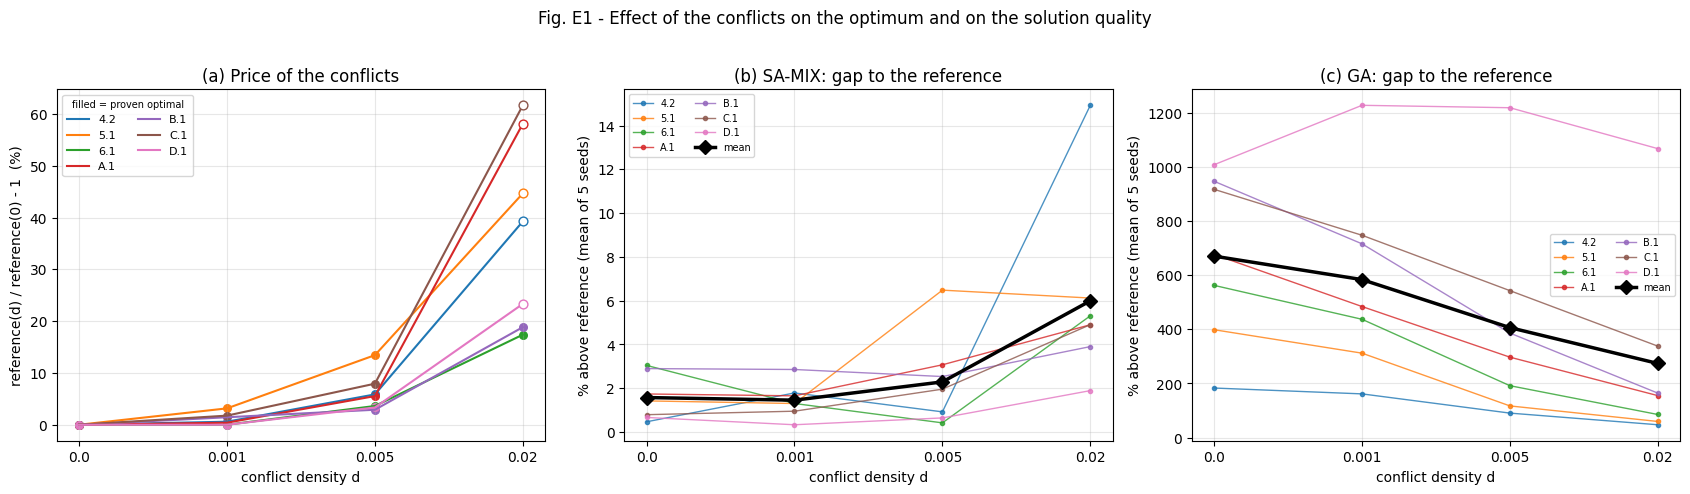

In [22]:
FIG_DIR.mkdir(exist_ok=True)
D_POS = {d: k for k, d in enumerate(DENSITIES)}
D_LAB = [str(d) for d in DENSITIES]
CLS_COLORS = dict(zip(["4", "5", "6", "A", "B", "C", "D"], plt.cm.tab10.colors))
M_COLORS = {"SA-MIX": "#1f77b4", "GA": "#d62728"}


def _xaxis(ax):
    ax.set_xticks(range(len(DENSITIES)))
    ax.set_xticklabels(D_LAB)
    ax.set_xlabel("conflict density d")
    ax.grid(alpha=0.3)


def _save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ---- Fig. E1 -----------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for l, g in sc.groupby("instance"):
    g = g.sort_values("density")
    x = g["density"].map(D_POS)
    ax[0].plot(x, g["price_%"], "-", color=CLS_COLORS[l[0]], lw=1.5, label=l)
    ax[0].scatter(x[g["ref_optimal"]], g["price_%"][g["ref_optimal"]], color=CLS_COLORS[l[0]], s=30)
    ax[0].scatter(x[~g["ref_optimal"]], g["price_%"][~g["ref_optimal"]], facecolors="white",
                  edgecolors=CLS_COLORS[l[0]], s=40, zorder=3)
ax[0].set(title="(a) Price of the conflicts", ylabel="reference(d) / reference(0) - 1  (%)")
ax[0].legend(fontsize=8, ncol=2, title="filled = proven optimal", title_fontsize=7)
_xaxis(ax[0])
for a, m in zip(ax[1:], METHODS):
    p = per[per["method"] == m]
    for l, g in p.groupby("instance"):
        g = g.sort_values("density")
        a.plot(g["density"].map(D_POS), g["gap_mean"], "-o", color=CLS_COLORS[l[0]], lw=1, ms=3, alpha=0.8, label=l)
    mean = p.groupby("density")["gap_mean"].mean()
    a.plot(mean.index.map(D_POS), mean.values, "-D", color="black", lw=2.5, ms=7, label="mean")
    a.set(title=f"({'bc'[METHODS.index(m)]}) {m}: gap to the reference", ylabel="% above reference (mean of 5 seeds)")
    a.legend(fontsize=7, ncol=2)
    _xaxis(a)
fig.suptitle("Fig. E1 - Effect of the conflicts on the optimum and on the solution quality", y=1.02)
_save(fig, "ext_conflicts_E1_quality")

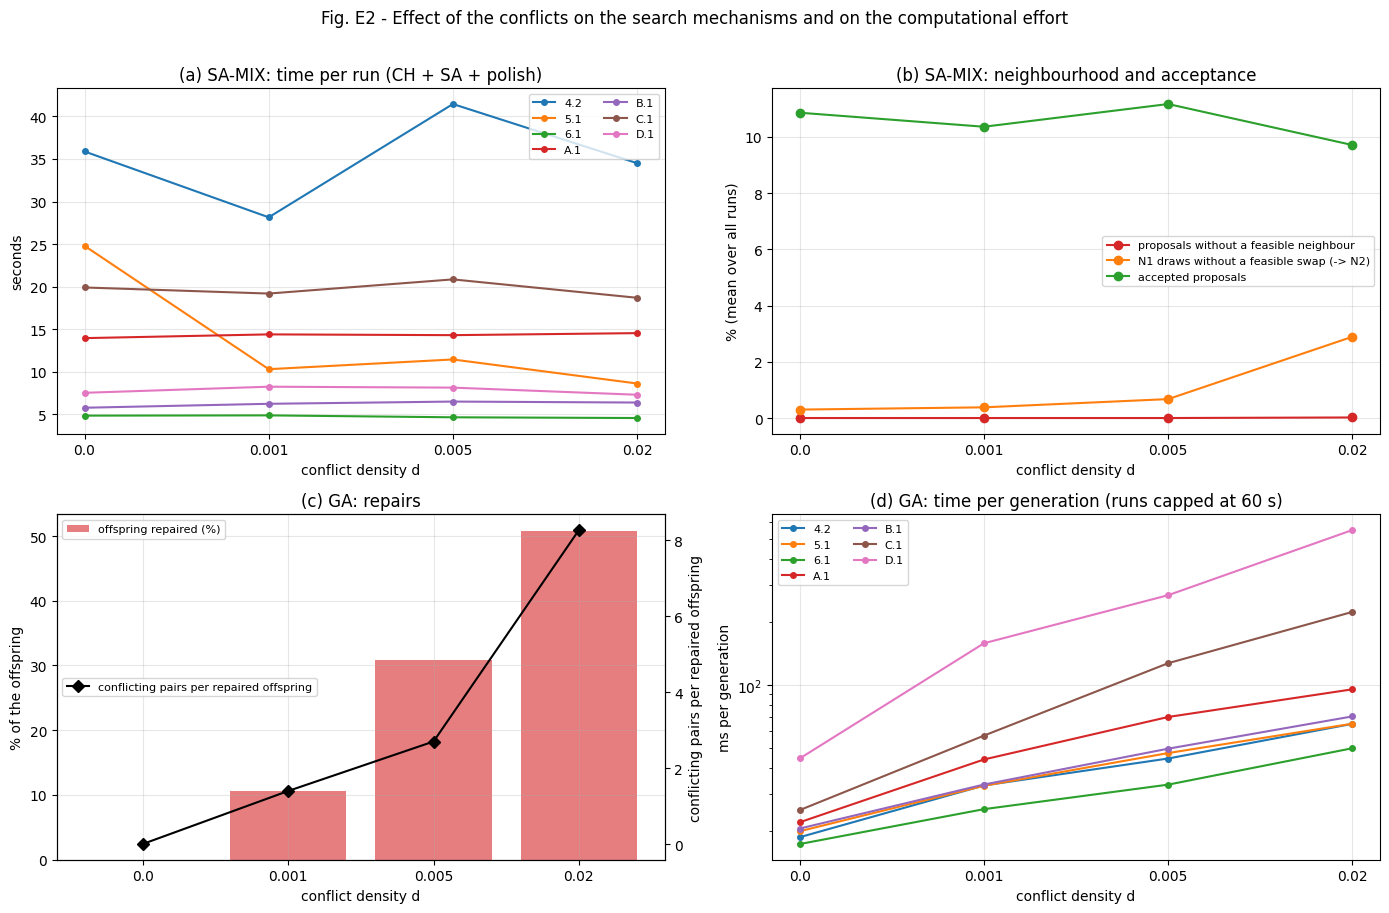

In [23]:
# ---- Fig. E2 -----------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
sa_, ga_ = res[res["method"] == "SA-MIX"], res[res["method"] == "GA"]
for l, g in sa_.groupby("instance"):
    t = g.groupby("density")["time_s"].mean()
    ax[0, 0].plot(t.index.map(D_POS), t.values, "-o", color=CLS_COLORS[l[0]], ms=4, label=l)
ax[0, 0].set(title="(a) SA-MIX: time per run (CH + SA + polish)", ylabel="seconds")
ax[0, 0].legend(fontsize=8, ncol=2)
rates = sa_.groupby("density")[["no_neighbour_rate", "n1_fail_rate", "accept_rate"]].mean() * 100
for c, lab, col in (("no_neighbour_rate", "proposals without a feasible neighbour", "tab:red"),
                    ("n1_fail_rate", "N1 draws without a feasible swap (-> N2)", "tab:orange"),
                    ("accept_rate", "accepted proposals", "tab:green")):
    ax[0, 1].plot(rates.index.map(D_POS), rates[c], "-o", color=col, label=lab)
ax[0, 1].set(title="(b) SA-MIX: neighbourhood and acceptance", ylabel="% (mean over all runs)")
ax[0, 1].legend(fontsize=8)
g_ = ga_.groupby("density")[["repair_rate", "conflicts_per_repair", "repair_fail_rate"]].mean()
ax[1, 0].bar(g_.index.map(D_POS), 100 * g_["repair_rate"], color="tab:red", alpha=0.6, label="offspring repaired (%)")
ax[1, 0].set(title="(c) GA: repairs", ylabel="% of the offspring")
tw = ax[1, 0].twinx()
tw.plot(g_.index.map(D_POS), g_["conflicts_per_repair"], "-D", color="black", label="conflicting pairs per repaired offspring")
tw.set_ylabel("conflicting pairs per repaired offspring")
ax[1, 0].legend(loc="upper left", fontsize=8)
tw.legend(loc="center left", fontsize=8)
for l, g in ga_.groupby("instance"):
    t = g.groupby("density")["time_per_gen_ms"].mean()
    ax[1, 1].plot(t.index.map(D_POS), t.values, "-o", color=CLS_COLORS[l[0]], ms=4, label=l)
ax[1, 1].set(title=f"(d) GA: time per generation (runs capped at {GA_TIME_S} s)", ylabel="ms per generation", yscale="log")
ax[1, 1].legend(fontsize=8, ncol=2)
for a in ax.ravel():
    _xaxis(a)
fig.suptitle("Fig. E2 - Effect of the conflicts on the search mechanisms and on the computational effort", y=1.01)
_save(fig, "ext_conflicts_E2_mechanisms")

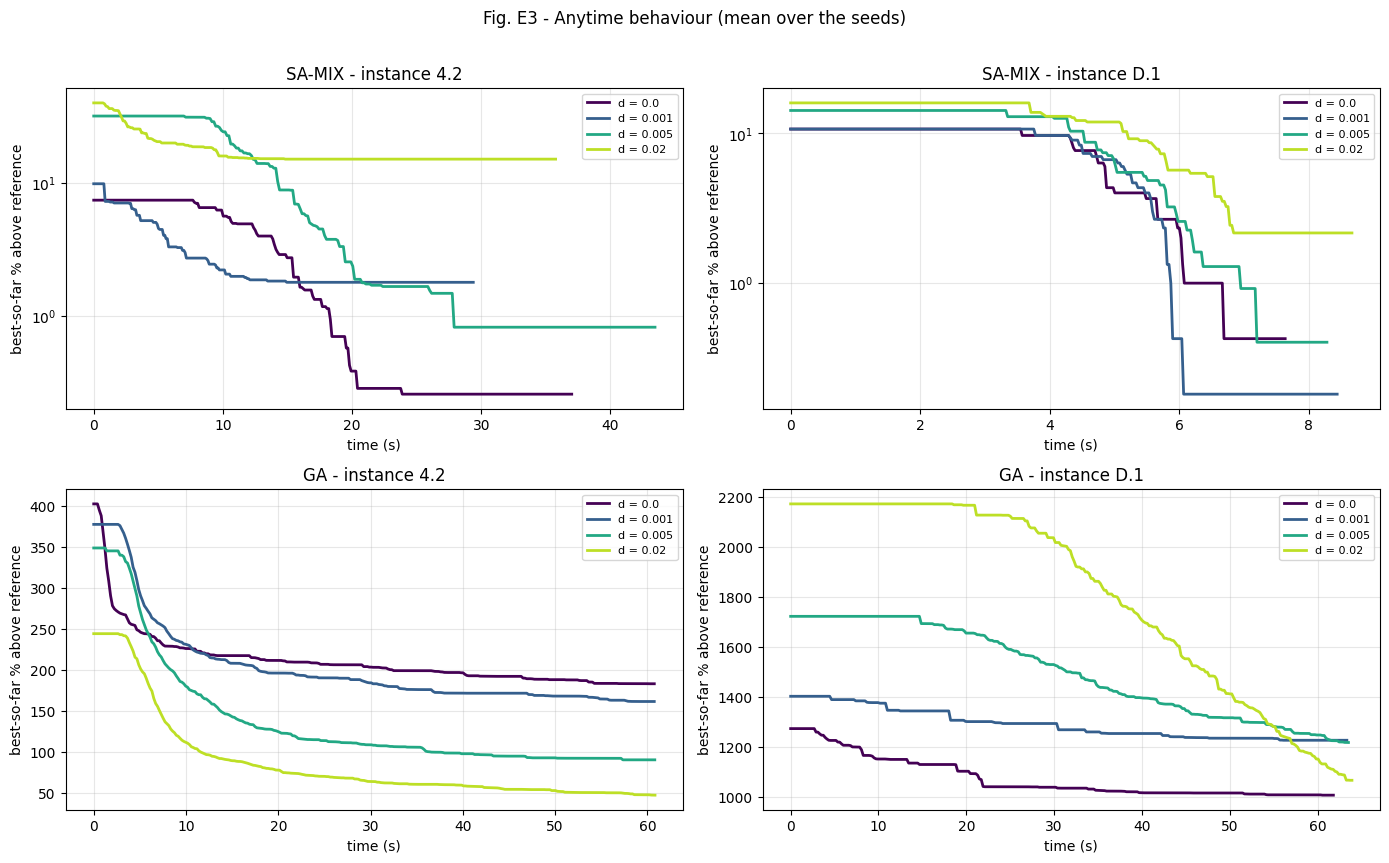

In [24]:
# ---- Fig. E3 -----------------------------------------------------------------------------------------------------
ANYTIME_LABELS = [l for l in ("4.2", "D.1") if l in EXP_LABELS]
D_COLORS = dict(zip(DENSITIES, plt.cm.viridis(np.linspace(0, 0.9, len(DENSITIES)))))
if histories and ANYTIME_LABELS:
    fig, ax = plt.subplots(2, len(ANYTIME_LABELS), figsize=(7 * len(ANYTIME_LABELS), 8.5), squeeze=False)
    ref_of = sc.set_index(["instance", "density"])["ref"]
    for r, m in enumerate(METHODS):
        for c, l in enumerate(ANYTIME_LABELS):
            a = ax[r, c]
            for d in DENSITIES:
                curves = [histories[k] for k in histories if k[0] == l and k[1] == d and k[2] == m]
                if not curves:
                    continue
                ref = ref_of[(l, d)]
                tmax = max(cv[-1, 0] for cv in curves)
                grid = np.linspace(0, tmax, 300)
                ys = []
                for cv in curves:
                    idx = np.clip(np.searchsorted(cv[:, 0], grid, side="right") - 1, 0, None)
                    ys.append(100 * (cv[idx, 1] - ref) / ref)
                a.plot(grid, np.mean(ys, axis=0), color=D_COLORS[d], lw=2, label=f"d = {d}")
            a.set(title=f"{m} - instance {l}", xlabel="time (s)", ylabel="best-so-far % above reference")
            if m == "SA-MIX":
                a.set_yscale("symlog", linthresh=1)
            a.grid(alpha=0.3)
            a.legend(fontsize=8)
    fig.suptitle("Fig. E3 - Anytime behaviour (mean over the seeds)", y=1.01)
    _save(fig, "ext_conflicts_E3_anytime")

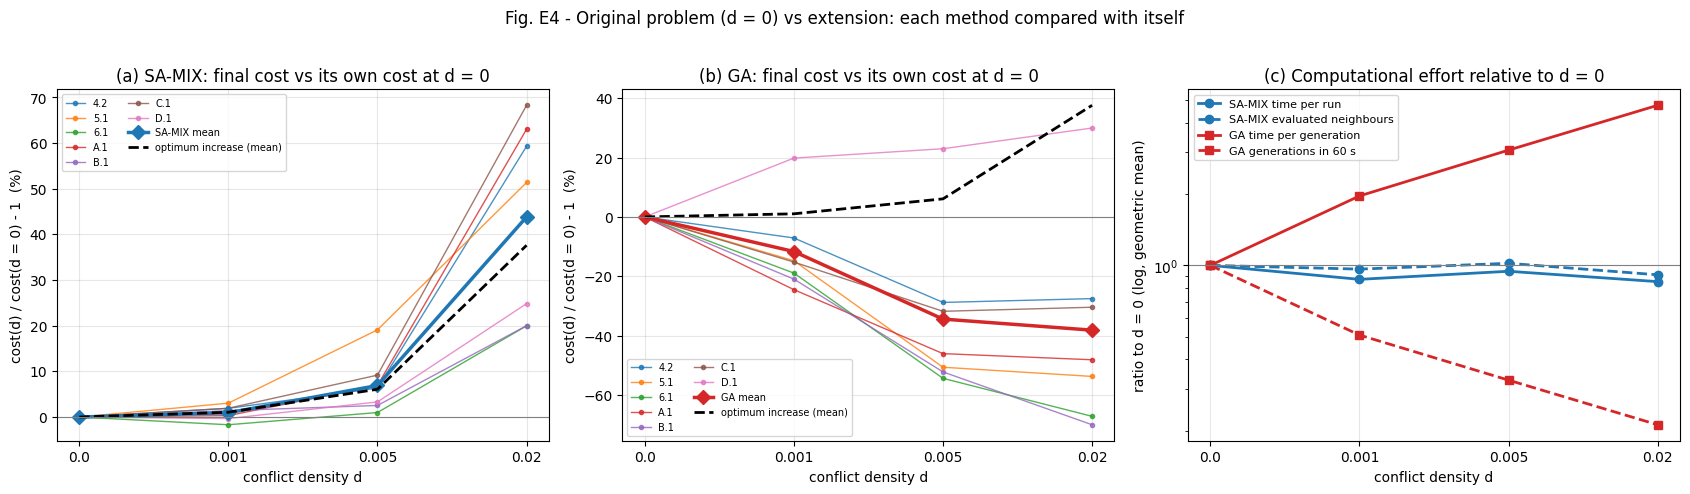

Mean cost increase over the instances relative to d = 0 (%); excess = method increase - optimum increase


method,GA,SA-MIX,optimum (MILP),SA-MIX excess,GA excess,SA-MIX time ratio,GA ms/gen ratio
density,,,,,,,
0.000,0.00,0.00,0.00,0.00,0.00,1.00,1.00
0.001,-11.66,0.94,1.05,-0.11,-12.71,0.87,1.96
0.005,-34.42,6.91,6.09,0.82,-40.51,0.94,3.07
0.020,-38.15,43.82,37.61,6.21,-75.76,0.85,4.75


In [25]:
# ---- Fig. E4: original problem vs extension, each method against itself ----------------------------------------
own = per.pivot_table(index=["instance", "density"], columns="method", values="cost_mean")
own = 100 * (own / own.xs(0.0, level="density").reindex(own.index.get_level_values("instance")).values - 1)
own["optimum (MILP)"] = sc.set_index(["instance", "density"])["price_%"].reindex(own.index).values
eff = res.groupby(["instance", "density", "method"])[["time_s", "evaluations", "time_per_gen_ms", "generations"]].mean()
eff = eff / eff.xs(0.0, level="density").reindex(
    pd.MultiIndex.from_arrays([eff.index.get_level_values(0), eff.index.get_level_values(2)])).values
geo = lambda s: float(np.exp(np.log(s.dropna()).mean())) if s.notna().any() else np.nan

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ref_mean = own["optimum (MILP)"].groupby("density").mean()
for a, m in zip(ax[:2], METHODS):
    for l in EXP_LABELS:
        g = own.xs(l, level="instance")[m]
        a.plot(g.index.map(D_POS), g.values, "-o", color=CLS_COLORS[l[0]], lw=1, ms=3, alpha=0.8, label=l)
    mm = own[m].groupby("density").mean()
    a.plot(mm.index.map(D_POS), mm.values, "-D", color=M_COLORS[m], lw=2.5, ms=7, label=f"{m} mean")
    a.plot(ref_mean.index.map(D_POS), ref_mean.values, "--", color="black", lw=2, label="optimum increase (mean)")
    a.axhline(0, color="grey", lw=0.8)
    a.set(title=f"({'ab'[METHODS.index(m)]}) {m}: final cost vs its own cost at d = 0",
          ylabel="cost(d) / cost(d = 0) - 1  (%)")
    a.legend(fontsize=7, ncol=2)
for col, m, lab, mk in (("time_s", "SA-MIX", "SA-MIX time per run", "-o"),
                        ("evaluations", "SA-MIX", "SA-MIX evaluated neighbours", "--o"),
                        ("time_per_gen_ms", "GA", "GA time per generation", "-s"),
                        ("generations", "GA", f"GA generations in {GA_TIME_S} s", "--s")):
    e = eff.xs(m, level="method")[col].groupby("density").apply(geo)
    ax[2].plot(e.index.map(D_POS), e.values, mk, color=M_COLORS[m], lw=2, label=lab)
ax[2].axhline(1, color="grey", lw=0.8)
ax[2].set(title="(c) Computational effort relative to d = 0", ylabel="ratio to d = 0 (log, geometric mean)",
          yscale="log")
ax[2].legend(fontsize=8)
for a in ax:
    _xaxis(a)
fig.suptitle("Fig. E4 - Original problem (d = 0) vs extension: each method compared with itself", y=1.02)
_save(fig, "ext_conflicts_E4_original_vs_extension")

tab = own.groupby("density").mean()
for m in METHODS:
    tab[f"{m} excess"] = tab[m] - tab["optimum (MILP)"]
tab["SA-MIX time ratio"] = eff.xs("SA-MIX", level="method")["time_s"].groupby("density").apply(geo)
tab["GA ms/gen ratio"] = eff.xs("GA", level="method")["time_per_gen_ms"].groupby("density").apply(geo)
print("Mean cost increase over the instances relative to d = 0 (%); excess = method increase - optimum increase")
display(tab.round(2))

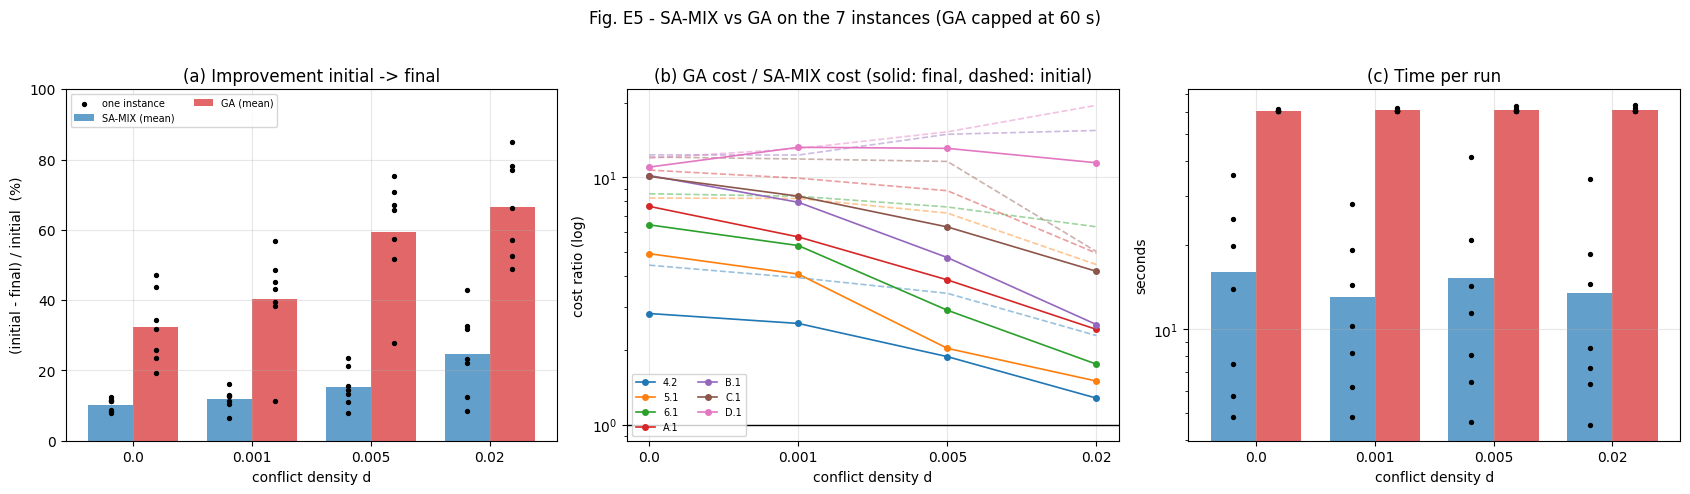

initial           cost        improv_%        time_s       
method       GA SA-MIX      GA SA-MIX       GA SA-MIX     GA SA-MIX
density                                                            
0.000    2026.8  244.4  1326.7  218.7     32.2   10.2   60.8   16.1
0.001    2025.3  255.6  1138.9  221.7     40.4   11.8   61.0   13.0
0.005    2126.6  288.3   838.5  236.6     59.4   15.3   61.2   15.3
0.020    2276.1  476.0   805.8  334.8     66.4   24.8   61.3   13.5

In [26]:
# ---- Fig. E5 -----------------------------------------------------------------------------------------------------
def add_improvement(df):
    """initial = constructive start (SA-MIX) or best of the initial population (GA); improvement in % of it."""
    df = df.copy()
    df["initial"] = df["start_cost"].where(df["method"] == "SA-MIX", df["init_best"])
    df["improv_%"] = 100 * (df["initial"] - df["cost"]) / df["initial"]
    return df


res = add_improvement(res)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
w = 0.38
for k, m in enumerate(METHODS):
    pts = res[res["method"] == m].groupby(["instance", "density"])[["improv_%", "time_s"]].mean().reset_index()
    off = (k - 0.5) * w
    for a, col in ((ax[0], "improv_%"), (ax[2], "time_s")):
        mean = pts.groupby("density")[col].mean()
        a.bar(mean.index.map(D_POS) + off, mean.values, w, color=M_COLORS[m], alpha=0.7, label=f"{m} (mean)")
        a.scatter(pts["density"].map(D_POS) + off, pts[col], color="black", s=8, zorder=3,
                  label="one instance" if k == 0 else None)
ax[0].set(title="(a) Improvement initial -> final", ylabel="(initial - final) / initial  (%)", ylim=(0, 100))
ax[2].set(title="(c) Time per run", ylabel="seconds", yscale="log")
ini = res.groupby(["instance", "density", "method"])[["initial", "cost"]].mean().unstack("method")
ratio_final = (ini["cost"]["GA"] / ini["cost"]["SA-MIX"]).rename("final").reset_index()
ratio_init = (ini["initial"]["GA"] / ini["initial"]["SA-MIX"]).rename("initial").reset_index()
for l in EXP_LABELS:
    for rr, col, ls in ((ratio_final, "final", "-o"), (ratio_init, "initial", "--")):
        g = rr[rr["instance"] == l].sort_values("density")
        ax[1].plot(g["density"].map(D_POS), g[col], ls, color=CLS_COLORS[l[0]], ms=4, lw=1.2,
                   alpha=1 if col == "final" else 0.45, label=l if col == "final" else None)
ax[1].axhline(1, color="black", lw=1)
ax[1].set(title="(b) GA cost / SA-MIX cost (solid: final, dashed: initial)", ylabel="cost ratio (log)", yscale="log")
ax[0].legend(fontsize=7, ncol=2, loc="upper left")
ax[1].legend(fontsize=7, ncol=2, loc="lower left")
for a in ax:
    _xaxis(a)
fig.suptitle(f"Fig. E5 - SA-MIX vs GA on the 7 instances (GA capped at {GA_TIME_S} s)", y=1.02)
_save(fig, "ext_conflicts_E5_sa_vs_ga")
display(res.groupby(["method", "density"])[["initial", "cost", "improv_%", "time_s"]].mean().unstack("method").round(1))

### 11.5 Statistical tests

Units = instances (per-instance mean gap over the seeds), paired by instance, Wilcoxon signed-rank test (exact for 7 pairs; the smallest attainable two-sided p-value is 0.016).
* **Effect of the extension within each method:** gap at density `d` vs gap at `d = 0`.
* **Relative degradation SA-MIX vs GA:** is the cost increase (relative to the same method at `d = 0`) larger for one of the two methods than for the other? The quantity compared is `cost(d) / cost(0) - 1` of each method, against the same quantity of the reference (the price of the conflicts).

In [27]:
def _wilcoxon(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if np.allclose(a, b):
        return 1.0
    try:
        return float(wilcoxon(a, b).pvalue)
    except ValueError:
        return np.nan


rows = []
for m in METHODS:
    piv = per[per["method"] == m].pivot(index="instance", columns="density", values="gap_mean")
    for d in DENSITIES[1:]:
        diff = piv[d] - piv[0.0]
        rows.append({"test": f"{m}: gap(d) vs gap(0)", "density": d, "mean gap(0)": piv[0.0].mean(),
                     "mean gap(d)": piv[d].mean(), "worse on": int((diff > 1e-9).sum()),
                     "better on": int((diff < -1e-9).sum()), "p (Wilcoxon)": _wilcoxon(piv[d], piv[0.0])})

cm = per.pivot_table(index=["instance", "density"], columns="method", values="cost_mean")
rel = cm / cm.xs(0.0, level="density").reindex(cm.index.get_level_values("instance")).values - 1
rel["reference"] = sc.set_index(["instance", "density"])["price_%"].reindex(rel.index).values / 100
for d in DENSITIES[1:]:
    r_ = rel.xs(d, level="density")
    rows.append({"test": "cost increase SA-MIX vs GA", "density": d, "mean SA-MIX": 100 * r_["SA-MIX"].mean(),
                 "mean GA": 100 * r_["GA"].mean(), "mean reference": 100 * r_["reference"].mean(),
                 "SA-MIX larger on": int((r_["SA-MIX"] > r_["GA"] + 1e-9).sum()),
                 "GA larger on": int((r_["GA"] > r_["SA-MIX"] + 1e-9).sum()),
                 "p (Wilcoxon)": _wilcoxon(r_["SA-MIX"], r_["GA"])})
tests = pd.DataFrame(rows)
display(tests.round(4))

,test,density,mean gap(0),mean gap(d),worse on,better on,p (Wilcoxon),mean SA-MIX,mean GA,mean reference,SA-MIX larger on,GA larger on
0,SA-MIX: gap(d) vs gap(0),0.001,1.5761,1.4557,2.0,5.0,0.5781,NaN,NaN,NaN,NaN,NaN
1,SA-MIX: gap(d) vs gap(0),0.005,1.5761,2.2905,4.0,3.0,0.4688,NaN,NaN,NaN,NaN,NaN
2,SA-MIX: gap(d) vs gap(0),0.020,1.5761,5.9930,7.0,0.0,0.0156,NaN,NaN,NaN,NaN,NaN
3,GA: gap(d) vs gap(0),0.001,670.5532,583.7565,1.0,6.0,0.2188,NaN,NaN,NaN,NaN,NaN
4,GA: gap(d) vs gap(0),0.005,670.5532,406.2878,1.0,6.0,0.0469,NaN,NaN,NaN,NaN,NaN
5,GA: gap(d) vs gap(0),0.020,670.5532,273.7934,1.0,6.0,0.0312,NaN,NaN,NaN,NaN,NaN
6,cost increase SA-MIX vs GA,0.001,NaN,NaN,NaN,NaN,0.1562,0.9383,-11.6617,1.0507,6.0,1.0
7,cost increase SA-MIX vs GA,0.005,NaN,NaN,NaN,NaN,0.0312,6.9083,-34.4225,6.0880,6.0,1.0
8,cost increase SA-MIX vs GA,0.020,NaN,NaN,NaN,NaN,0.0312,43.8210,-38.1544,37.6091,6.0,1.0


In [28]:
# ---- export of the raw data -------------------------------------------------------------------------------------
summary.round(4).to_csv("scp_conflict_ext_summary.csv")
per.round(4).to_csv("scp_conflict_ext_per_scenario.csv", index=False)
sc.drop(columns="milp_solution").round(4).to_csv("scp_conflict_ext_scenarios.csv", index=False)
print("Saved: scp_conflict_ext_results.csv (every run), scp_conflict_ext_per_scenario.csv, "
      "scp_conflict_ext_summary.csv, scp_conflict_ext_scenarios.csv, scp_conflict_ext_milp.csv, "
      f"conflict graphs in {CONFLICT_DIR}/, figures in {FIG_DIR}/ext_conflicts_E*.png")

Saved: scp_conflict_ext_results.csv (every run), scp_conflict_ext_per_scenario.csv, scp_conflict_ext_summary.csv, scp_conflict_ext_scenarios.csv, scp_conflict_ext_milp.csv, conflict graphs in conflict_instances/, figures in figures/ext_conflicts_E*.png


## 12. Focused comparison on instance 4.2 with a longer GA budget

The 60 s cap of section 10 was a compromise for 140 GA runs. Here the two methods are compared on **one instance** (4.2, the instance used in all the previous assignments) and the GA gets **`FOCUS_GA_TIME_S = 600` s** per run (10 times more), 4 densities x 5 seeds = 20 new GA runs (about 50 min with 4 jobs, resumable). The SA-MIX runs are those of section 10: SA-MIX stops on its own schedule, so more time would not change them.

The comparison does not need a BKS. For a minimisation problem, each run is described by:
* **initial cost**: constructive start (SA-MIX) or best individual of the random initial population (GA);
* **final cost** (mean, best and std over the 5 seeds) and **improvement** `100 (initial - final) / initial`;
* **final cost relative to the other method**: `GA / SA-MIX`; the Mann-Whitney U test (5 vs 5 runs) says whether the difference is significant;
* **time** per run and, for the GA, the time of its last improvement.

The MILP value of section 5 is shown only as a line in the figures (proven optimum for `d <= 0.005`; for `d = 0.02` it is the best solution found in 120 s, and its lower bound is drawn too). The improvement percentages of the two methods must be read together with their starting points: the GA starts from a random cover, 2 to 10 times more expensive than the constructive start of SA-MIX, so a large improvement does not mean a good final solution.

In [29]:
FOCUS_LABEL = "4.2"
FOCUS_GA_TIME_S = 600
FOCUS_CSV = "scp_conflict_ext_focus_results.csv"
FOCUS_PKL = "scp_conflict_ext_focus_histories.pkl"

focus_scen = {k: v for k, v in scenarios.items() if k[0] == FOCUS_LABEL}
focus_ga = run_experiment(focus_scen, starts, methods=["GA"], path=FOCUS_CSV, hist_path=FOCUS_PKL,
                          ga_time_s=FOCUS_GA_TIME_S, recompute_key="focus")
focus_hist = pickle.load(open(FOCUS_PKL, "rb")) if Path(FOCUS_PKL).exists() else {}
print(f"{len(focus_ga)} long GA runs; all feasible and conflict-free: {bool(focus_ga['feasible'].all())}")

20 runs already in scp_conflict_ext_focus_results.csv; 0 to do (~0 min with 4 jobs).
20 long GA runs; all feasible and conflict-free: True


In [30]:
from scipy.stats import mannwhitneyu

GA_SHORT, GA_LONG = f"GA {GA_TIME_S} s", f"GA {FOCUS_GA_TIME_S} s"
F_METHODS = ["SA-MIX", GA_SHORT, GA_LONG]
F_COLORS = {"SA-MIX": M_COLORS["SA-MIX"], GA_SHORT: "#f4a582", GA_LONG: M_COLORS["GA"]}

base = results[results["instance"] == FOCUS_LABEL]
foc = pd.concat([base[base["method"] == "SA-MIX"],
                 base[base["method"] == "GA"].assign(method=GA_SHORT),
                 focus_ga.assign(method=GA_LONG)], ignore_index=True)
foc["initial"] = foc["start_cost"].where(foc["method"] == "SA-MIX", foc["init_best"])
foc["improv_%"] = 100 * (foc["initial"] - foc["cost"]) / foc["initial"]
milp_f = milp_df[milp_df["instance"] == FOCUS_LABEL].set_index("density")

ftab = (foc.groupby(["density", "method"], sort=False)
           .agg(initial=("initial", "mean"), final_mean=("cost", "mean"), final_best=("cost", "min"),
                final_std=("cost", "std"), improv_pct=("improv_%", "mean"), time_s=("time_s", "mean"),
                last_improv_s=("time_to_best_s", "mean"), generations=("generations", "mean"))
           .reindex(pd.MultiIndex.from_product([DENSITIES, F_METHODS], names=["density", "method"])))
ftab["MILP"] = [milp_f.loc[d, "milp_ub"] for d, _ in ftab.index]
ftab["MILP_optimal"] = [bool(milp_f.loc[d, "milp_optimal"]) for d, _ in ftab.index]
print(f"Instance {FOCUS_LABEL}: initial and final cost (5 seeds), improvement in %, time in s")
display(ftab.round(1))

rows = []
for d in DENSITIES:
    sa = foc[(foc["density"] == d) & (foc["method"] == "SA-MIX")]["cost"].values
    for gm in (GA_SHORT, GA_LONG):
        ga = foc[(foc["density"] == d) & (foc["method"] == gm)]["cost"].values
        rows.append({"density": d, "GA": gm, "SA-MIX mean": sa.mean(), "GA mean": ga.mean(),
                     "GA / SA-MIX": ga.mean() / sa.mean(), "GA better in": int((ga[:, None] < sa[None, :]).sum()),
                     "pairs": len(ga) * len(sa), "p (Mann-Whitney)": float(mannwhitneyu(ga, sa).pvalue)})
display(pd.DataFrame(rows).round(4))
ftab.round(3).to_csv("scp_conflict_ext_focus_summary.csv")

Instance 4.2: initial and final cost (5 seeds), improvement in %, time in s


initial  final_mean  final_best  final_std  improv_pct  \
density method                                                             
0.000   SA-MIX      582.0       514.4       512.0        3.3        11.6   
        GA 60 s    2570.6      1448.8      1345.0      102.2        43.6   
        GA 600 s   2570.6      1340.2      1249.0      112.1        47.9   
0.001   SA-MIX      625.0       524.2       515.0        6.6        16.1   
        GA 60 s    2457.2      1346.0      1237.0       85.7        45.3   
        GA 600 s   2457.2      1170.4      1090.0       79.6        52.4   
0.005   SA-MIX      715.0       547.0       542.0        6.6        23.5   
        GA 60 s    2430.2      1031.4       977.0       44.7        57.5   
        GA 600 s   2430.2       801.2       733.0       64.7        67.0   
0.020   SA-MIX     1069.0       819.4       794.0       17.6        23.3   
        GA 60 s    2452.6      1050.0       899.0      160.6        57.1   
        GA 600 s   2452.6       945.6       884.0       64.1        61.4   

                  time_s  last_improv_s  generations   MILP  MILP_optimal  
density method                                                             
0.000   SA-MIX      35.9            NaN          NaN  512.0          True  
        GA 60 s     60.6           52.0       3229.2  512.0          True  
        GA 600 s   600.5          467.3      31999.8  512.0          True  
0.001   SA-MIX      28.1            NaN          NaN  515.0          True  
        GA 60 s     60.7           51.4       1824.0  515.0          True  
        GA 600 s   600.7          473.3      18847.2  515.0          True  
0.005   SA-MIX      41.5            NaN          NaN  542.0          True  
        GA 60 s     60.6           50.0       1358.6  542.0          True  
        GA 600 s   600.7          442.0      13068.2  542.0          True  
0.020   SA-MIX      34.5            NaN          NaN  713.0         False  
        GA 60 s     60.7           54.5        925.4  713.0         False  
        GA 600 s   600.7          464.2      10084.6  713.0         False

,density,GA,SA-MIX mean,GA mean,GA / SA-MIX,GA better in,pairs,p (Mann-Whitney)
0,0.000,GA 60 s,514.4,1448.8,2.8165,0,25,0.0109
1,0.000,GA 600 s,514.4,1340.2,2.6054,0,25,0.0109
2,0.001,GA 60 s,524.2,1346.0,2.5677,0,25,0.0079
3,0.001,GA 600 s,524.2,1170.4,2.2327,0,25,0.0079
4,0.005,GA 60 s,547.0,1031.4,1.8856,0,25,0.0119
5,0.005,GA 600 s,547.0,801.2,1.4647,0,25,0.0119
6,0.020,GA 60 s,819.4,1050.0,1.2814,0,25,0.0119
7,0.020,GA 600 s,819.4,945.6,1.1540,0,25,0.0119


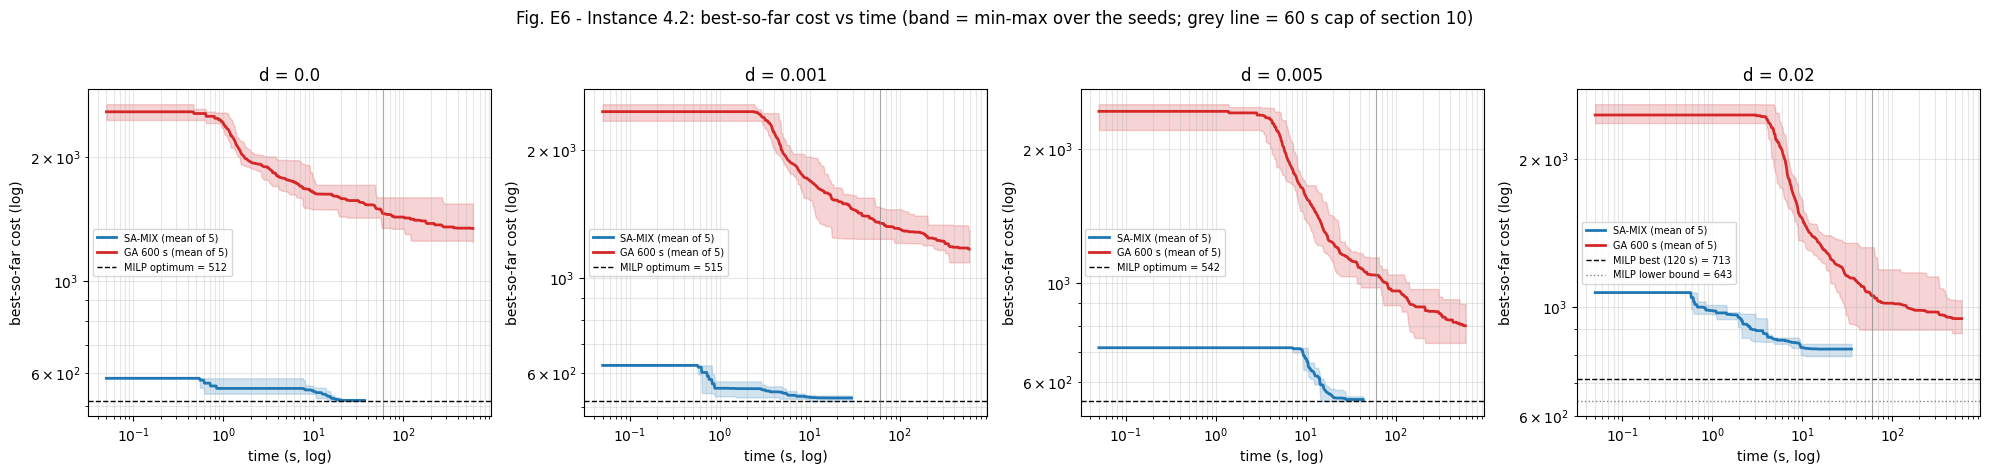

In [31]:
# ---- Fig. E6: convergence on the focus instance ------------------------------------------------------------------
T_MIN = 0.05                                             # log time axis starts here


def _mean_band(curves, grid):
    ys = []
    for cv in curves:
        idx = np.clip(np.searchsorted(cv[:, 0], grid, side="right") - 1, 0, None)
        y = cv[idx, 1].astype(float)
        y[grid > cv[-1, 0]] = cv[-1, 1]                      # finished runs keep their final cost
        ys.append(y)
    ys = np.array(ys)
    return ys.mean(0), ys.min(0), ys.max(0)


fig, ax = plt.subplots(1, len(DENSITIES), figsize=(5 * len(DENSITIES), 4.6), sharey=False)
grid = np.geomspace(T_MIN, FOCUS_GA_TIME_S * 1.05, 600)
for a, d in zip(ax, DENSITIES):
    sa_curves = []
    for s in EXP_SEEDS:
        cv = histories.get((FOCUS_LABEL, d, "SA-MIX", s))
        if cv is not None:                                   # prepend the constructive start
            row = base[(base["method"] == "SA-MIX") & (base["density"] == d) & (base["seed"] == s)].iloc[0]
            sa_curves.append(np.vstack([[0.0, row["start_cost"]], cv]))
    ga_curves = [focus_hist[k] for k in focus_hist if k[0] == FOCUS_LABEL and k[1] == d and k[2] == "GA"]
    for name, curves in (("SA-MIX", sa_curves), (GA_LONG, ga_curves)):
        if not curves:
            continue
        tmax = max(cv[-1, 0] for cv in curves)
        gg = grid[grid <= tmax]
        mean, lo, hi = _mean_band(curves, gg)
        a.plot(gg, mean, color=F_COLORS[name], lw=2, label=f"{name} (mean of {len(curves)})")
        a.fill_between(gg, lo, hi, color=F_COLORS[name], alpha=0.2)
    m = milp_f.loc[d]
    a.axhline(m["milp_ub"], color="black", ls="--", lw=1,
              label=f"MILP {'optimum' if m['milp_optimal'] else 'best (120 s)'} = {m['milp_ub']:.0f}")
    if not m["milp_optimal"]:
        a.axhline(m["milp_lb"], color="grey", ls=":", lw=1, label=f"MILP lower bound = {m['milp_lb']:.0f}")
    a.axvline(GA_TIME_S, color="grey", lw=0.8, alpha=0.6)
    a.set(xscale="log", yscale="log", title=f"d = {d}", xlabel="time (s, log)", ylabel="best-so-far cost (log)")
    a.grid(alpha=0.3, which="both")
    a.legend(fontsize=7)
fig.suptitle(f"Fig. E6 - Instance {FOCUS_LABEL}: best-so-far cost vs time (band = min-max over the seeds; "
             f"grey line = {GA_TIME_S} s cap of section 10)", y=1.02)
_save(fig, "ext_conflicts_E6_focus_convergence")

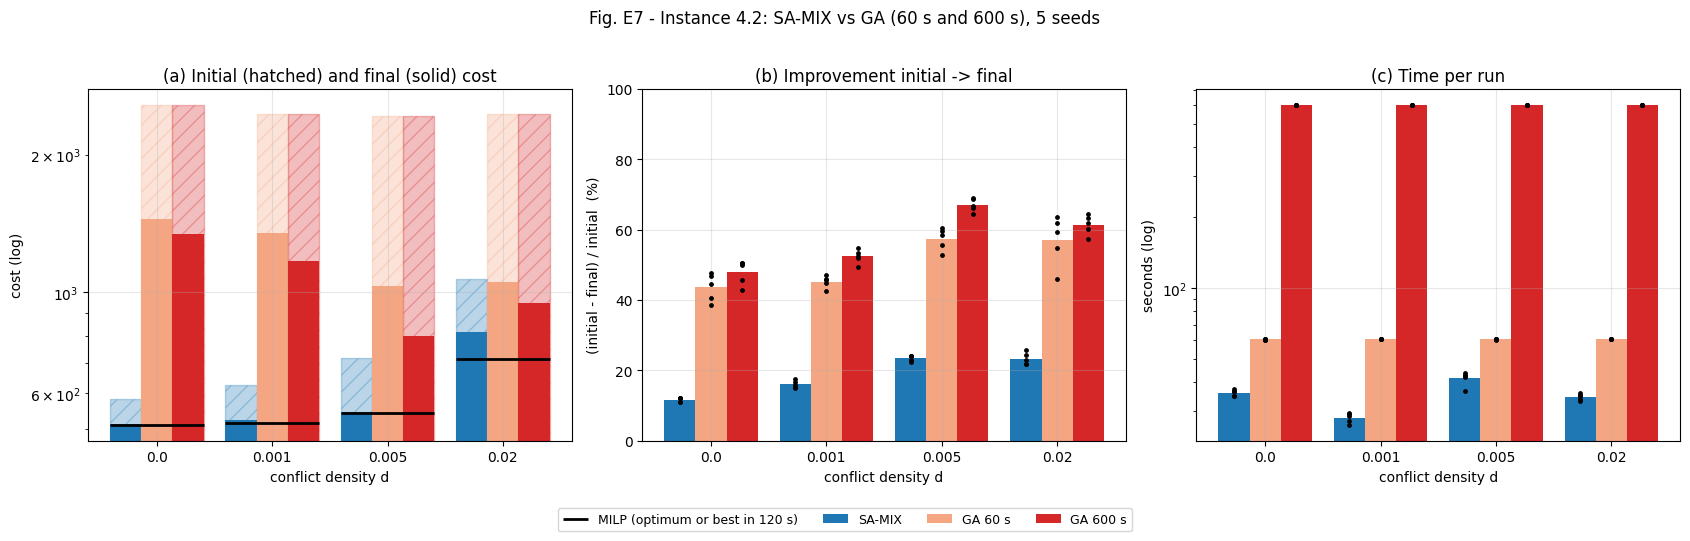

In [32]:
# ---- Fig. E7: initial vs final, improvement and time on the focus instance ---------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
w = 0.27
for k, m in enumerate(F_METHODS):
    t = ftab.xs(m, level="method")
    x = np.arange(len(DENSITIES)) + (k - 1) * w
    ax[0].bar(x, t["initial"], w, color=F_COLORS[m], alpha=0.3, hatch="//", edgecolor=F_COLORS[m])
    ax[0].bar(x, t["final_mean"], w, color=F_COLORS[m], label=m)
    ax[1].bar(x, t["improv_pct"], w, color=F_COLORS[m], label=m)
    ax[2].bar(x, t["time_s"], w, color=F_COLORS[m], label=m)
    for a, col in ((ax[1], "improv_%"), (ax[2], "time_s")):
        pts = foc[foc["method"] == m]
        a.scatter(pts["density"].map(D_POS) + (k - 1) * w, pts[col], color="black", s=6, zorder=3)
xs = np.arange(len(DENSITIES))
ax[0].hlines([milp_f.loc[d, "milp_ub"] for d in DENSITIES], xs - 1.5 * w, xs + 1.5 * w, colors="black", lw=2,
             label="MILP (optimum or best in 120 s)")
ax[0].set(title="(a) Initial (hatched) and final (solid) cost", ylabel="cost (log)", yscale="log")
ax[1].set(title="(b) Improvement initial -> final", ylabel="(initial - final) / initial  (%)", ylim=(0, 100))
ax[2].set(title="(c) Time per run", ylabel="seconds (log)", yscale="log")
for a in ax:
    _xaxis(a)
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), fontsize=9)
fig.suptitle(f"Fig. E7 - Instance {FOCUS_LABEL}: SA-MIX vs GA ({GA_TIME_S} s and {FOCUS_GA_TIME_S} s), 5 seeds", y=1.02)
_save(fig, "ext_conflicts_E7_focus_summary")

## 13. Discussion

All numbers below are means over the 7 instances (5 seeds each, GA capped at 60 s) unless the 4.2 focus study (section 12, GA 600 s) is named.

**1. Impact on the problem.** The conflicts make the problem harder and more expensive. The optimum rises by +1 %, +6 % and +38 % at `d` = 0.001, 0.005 and 0.02 (Fig. E1a), because the optimal cover of the standard SCP already contains 2, 8 and 31 conflicting pairs. The MILP proves optimality in 23 of the 28 scenarios. At `d = 0.02` it stops at the 120 s limit on 5 of the 7 instances, with gaps of 10-40 % between incumbent and bound: the conflict constraints destroy the strong LP relaxation of the SCP. Feasibility is no longer guaranteed (assumption A5), and the constructive heuristics need ejections to reach a cover.

**2. Impact on SA-MIX (feasible-space search).**
* *Quality*: SA-MIX follows the optimum. Its final cost rises by +0.9 %, +6.9 % and +43.8 % against +1.1 %, +6.1 % and +37.6 % for the optimum (Fig. E4a). Its gap goes from 1.6 % to 6.0 %, a significant deterioration only at `d = 0.02` (worse on 7/7 instances, Wilcoxon p = 0.016). The worst case is 4.2 at `d = 0.02` (+15 % above the MILP solution). There, the constructive start is already 50 % above it and the calibrated cooling schedule is too short to recover.
* *Computation*: unchanged. The time per run is 0.85-0.94 times that at `d = 0` (Fig. E4c), with the same number of evaluated neighbours. The compatibility test costs one lookup per candidate set, and conflicts reduce the number of candidate moves.
* *Mechanism*: the neighbourhood survives. Proposals without any feasible neighbour stay at 0.02 %. The share of N1 draws that find no compatible swap rises from 0.3 % to 2.9 % (Fig. E2b), and the MIX variant then falls back on N2 (remove + compatible repair). This fallback is the reason the method is so robust.

**3. Impact on the GA (repair approach).**
* *Computation*: the GA pays a lot. At `d = 0.02`, 51 % of the offspring contain a conflicting pair (8 pairs each on average). A generation costs 4.75 times more than at `d = 0`, so the GA completes about 5 times fewer generations in the same time (Fig. E2c-d, E4c).
* *Quality*: the GA nevertheless ends **cheaper** than at `d = 0`: -12 %, -34 % and -38 % (better on 6 of 7 instances, p = 0.031; D.1 is the exception: its final cost rises roughly with the optimum). This is not a time-cap artefact. With 600 s on 4.2 the effect persists (1340 at `d = 0` vs 801 at `d = 0.005`).
* *Explanation (measured)*: the pure GA has no redundancy elimination after crossover and mutation. An offspring of two parents is the union of their genes, about 92 sets on 4.2, which makes it about 30 % more expensive than its parents. The repair drops the conflicting sets and re-covers **only the elements left uncovered**. On repaired offspring it removes 10-17 sets and lowers the cost by 4 % (4.2, d = 0.005), 11 % (4.2, d = 0.02) and 19 % (D.1, d = 0.02). The repair therefore acts as an implicit improvement operator, and its effect grows with the density. The measured "impact of the extension" on the GA is the sum of a harder problem and this side effect of the repair. An ablation that applies the same drop-and-recover step at `d = 0` would separate the two.

**4. SA-MIX vs GA.**
* *Absolute quality*: SA-MIX is clearly better in every scenario, as at `d = 0`. On 4.2 the GA is 2.6 times more expensive at `d = 0` and 1.15 times at `d = 0.02`, even with 600 s against about 35 s. It never beats SA-MIX in any of the 25 run pairs at any density (Mann-Whitney p ≈ 0.01; Fig. E6-E7). The gap narrows with the density for the reason of item 3, not because the GA handles conflicts better.
* *Improvement from the initial solution*: 10-25 % for SA-MIX and 32-66 % for the GA (Fig. E5a). The larger value comes from a random start that is 2-10 times more expensive, not from a better search.
* *How the constraint is handled*: SA moves one or two sets at a time and can test compatibility **before** a move, so it never leaves the feasible space and the conflicts cost almost nothing. The GA recombines whole halves of two solutions. Crossover cannot check the pairs it creates, so their number grows with the number of sets and with the density, and feasibility has to be restored **afterwards**. Effort moves from search to repair, and the repair also changes the search (item 3).
* *Sensitivity*: SA-MIX is sensitive to the quality of its constructive start, which degrades with the density. The GA does not depend on its start but pays per generation.

**5. Challenges.**
* *No benchmark*: there is no benchmark for the extension. The conflict graphs are synthetic, nested and seeded so that they can be reproduced. The reference had to come from an exact MILP, which loses optimality proofs at `d = 0.02`.
* *Possible infeasibility*: feasibility is not guaranteed, so every component (CH1-CH3, N1/N2, repair) needed a dead-end policy (ejection) and a bound on it.
* *Speed*: keeping the conflict checks cheap required incremental conflict counters for SA and vectorised counting for the GA repair. A naive pairwise check made the GA several times slower.
* *Fair comparison*: SA stops on its own schedule and the GA on time, so the main comparison is each method against itself (Fig. E4), complemented by the 600 s focus study.
* *Statistics*: with 7 instances and 5 seeds the tests have little power (the smallest attainable p is 0.016). The findings at `d = 0.001` should be read as trends.